# Домашнее задание 2. Вариант CV: детекция на YOLO

**Дедлайн:** вс 22.11.2026, 23:59.

Задача - взять предобученный детектор, найти свой датасет, привести разметку к нужному формату, дообучить модель, честно измерить качество и разобрать ошибки. Код YOLO и конвертации разметки был на семинаре 5-6 (yolo26n, PennFudan, `to_yolo`), им можно пользоваться со ссылкой на источник.

- Вы выбираете **один** вариант ДЗ2: этот (CV) или NLP. Номера задач и баллы в вариантах совпадают
- Заполняйте места с `# ваш код` и ячейки «Ответ». Сигнатуры функций и открытые тесты сохраняйте, свои ячейки добавлять можно. Открытые тесты проверяют часть контракта, при оценке будут и другие входы
- После вопроса нужны наблюдение с числами, объяснение и, если нужно, ограничение вывода. Обычно хватает 2-4 предложений. Отсутствие ожидаемого эффекта - нормальный результат, если эксперимент корректный и вы это обсудили
- Датасет ищете сами (подсказки в 2.1): открытая лицензия, не PennFudan и не учебные coco8 / coco128
- Свой код обязателен в 1.2 (параметры по блокам), 2.2 (конвертация и тест), 3.1 (тривиальный бейзлайн), 5.1 (разбор ошибок). Для обучения и стандартных метрик пользуйтесь ultralytics
- `FAST_MODE = True` - проверка кода на маленьком бюджете (подмножество train, 1-2 эпохи, imgsz 320), должен укладываться в 5 минут на Colab T4. Финальные эксперименты - с `FAST_MODE = False`, ориентир - около часа на T4
- Бонусы 6.1-6.5 включаются через `BONUS_TASKS`. За бонусы суммарно можно получить до 4 баллов из 5.5 предложенных. Выключенные бонусы пропускаются, даже если решения пустые
- Для полной сдачи: Restart & Run All с `FAST_MODE = False`, сохранить outputs, приложить каталог `artifacts/`, который создается перед бонусами. Укажите устройство (Colab T4, Kaggle и т.п.). Если сдаете частичное решение, перечислите нерешенные задачи в ячейке ниже и приложите то, что есть, ошибки не скрывайте. Баллы ставятся по задачам, одна ошибка не обнуляет остальные
- Сдача как в ДЗ1: свой публичный GitHub-репозиторий с ноутбуком (с outputs) и каталогом `artifacts/`, ссылка - в Google-форму. Датасет в репозиторий класть не нужно, достаточно кода скачивания
- Только открытые модели и данные, лицензию укажите в 1.1 / 2.1. Можно пользоваться документацией ultralytics, материалами курса и кодом семинаров (укажите источник). Работа индивидуальная

| раздел | задачи | баллы |
|---|---|---|
| 1. Модель | 1.1 модель и версия (1.5) · 1.2 архитектура (2.5) | 4 |
| 2. Данные | 2.1 свой датасет (1.5) · 2.2 формат разметки (2.5) | 4 |
| 3. Бейзлайн | 3.1 до дообучения (2) | 2 |
| 4. Дообучение | 4.1 обучение (3) · 4.2 метрики (3) | 6 |
| 5. Анализ | 5.1 разбор ошибок (2) · 5.2 абляция (1) · 5.3 выводы (1) | 4 |
| 6*. Бонусы | 6.1 доразметка (1.5) · 6.2 RT-DETR (1) · 6.3 сдвиг домена (1) · 6.4 ONNX и скорость (1) · 6.5 пороги (1) | до +4 |
| итого | | 20 + 4 |

Примерный план: первая неделя - разделы 1-3 (модель, датасет, конвертация, бейзлайн), вторая - обучение, метрики, разбор ошибок, абляция и финальный прогон.

**Сведения о сдаче.** Укажите устройство, датасет (ссылка и лицензия), внешние источники кода и нерешенные задачи (если есть).

**Ответ:** Вариант CV, выполнены обязательные задачи 1.1–5.3 и бонусы 6.2–6.5 (4 балла); 6.1 не выбран. Устройство: Apple M3 Pro, **CPU**, PyTorch 2.15.0; MPS в среде выполнения недоступен. YOLO26n, ultralytics==8.4.216; идентификаторы весов и данные окружения сохранены в artifacts/environment.json. Датасет: [BCCD](https://github.com/Shenggan/BCCD_Dataset), [MIT](https://github.com/Shenggan/BCCD_Dataset/blob/master/LICENSE), ревизия `d272fb14cdff6e473fafeeeba32aba5f560e9e43`; train/val/test = 254/54/56. Финальный прогон: FAST_MODE=False, outputs сохранены, незавершенных выбранных задач нет. Источники: исходный шаблон ДЗ, [документация YOLO26](https://docs.ultralytics.com/models/yolo26/), [обучение](https://docs.ultralytics.com/modes/train/), [валидация](https://docs.ultralytics.com/modes/val/), [RT-DETR](https://docs.ultralytics.com/models/rtdetr/), [экспорт](https://docs.ultralytics.com/modes/export/), [исходники Ultralytics](https://github.com/ultralytics/ultralytics). Конвертация, подсчет параметров, эвристика и разбор ошибок реализованы в соответствующих ячейках.

In [1]:
# Colab / Kaggle: ultralytics ставится один раз (torch, numpy, matplotlib, scipy там уже есть)
import importlib.util, importlib.metadata, subprocess, sys
if importlib.util.find_spec('ultralytics') is None or importlib.metadata.version('ultralytics') != '8.4.216':
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'ultralytics==8.4.216'], check=True)

import platform
import urllib.request
import zipfile
import io
import copy
import yaml
from IPython.display import display, Markdown
import csv
import hashlib
import json
import math
import os
os.environ.setdefault('PYTORCH_ENABLE_MPS_FALLBACK', '1')
os.environ.setdefault('YOLO_CONFIG_DIR', os.path.abspath('data/ultralytics_config'))
os.environ.setdefault('MPLCONFIGDIR', os.path.abspath('data/matplotlib_cache'))
os.environ.setdefault('XDG_CACHE_HOME', os.path.abspath('data/cache'))
import random
import shutil
import time
import xml.etree.ElementTree as ET
from collections import Counter
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image
from scipy import ndimage

import torch
import torchvision
torch.set_num_threads(4)
from torchvision.ops import box_iou
import ultralytics
from ultralytics import YOLO

plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 12
try:   # картинки в outputs - jpeg: с фотографиями ноутбук в разы легче, чем с png
    from matplotlib_inline.backend_inline import set_matplotlib_formats
    set_matplotlib_formats('jpeg')
except ImportError:
    pass

DEVICE = 0 if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu')
DEVICE_NAME = torch.cuda.get_device_name(0) if torch.cuda.is_available() else str(DEVICE)
if DEVICE == 'mps':
    DEVICE_NAME = f'Apple Silicon, MPS ({platform.platform()})'
print(f'ultralytics {ultralytics.__version__}, torch {torch.__version__}, device: {DEVICE_NAME}')

ultralytics 8.4.216, torch 2.15.0, device: cpu


In [2]:
FAST_MODE = False   # True - отладка, False - финальный прогон
BONUS_TASKS = {'6.2', '6.3', '6.4', '6.5'}     # например {'6.3', '6.5'}; пустое множество отключает все бонусы
assert BONUS_TASKS <= {'6.1', '6.2', '6.3', '6.4', '6.5'}

SEED = 0
DATA_ROOT = Path('data')
RUNS = Path('runs_hw2')
IMGSZ = 320 if FAST_MODE else 640
EPOCHS = 2 if FAST_MODE else 40
BATCH = 8 if FAST_MODE else 8
N_TRAIN_FAST = 64            # сколько картинок train берется в FAST_MODE
WORKERS = 0   # на Windows воркеры DataLoader в Jupyter часто зависают
RUN_TIMES = {}


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


set_seed()

Общие функции: рисование боксов и mAP50 для своих предсказаний (нужна в 3.1, где предсказания делает не ultralytics). Предсказания и разметка одной картинки - словари `dict(boxes=(n, 4) xyxy в пикселях, labels=(n,), scores=(n,))`, у разметки нет `scores`.

In [3]:
COLORS = plt.cm.tab10.colors


def draw_boxes(ax, image, boxes, labels, names, scores=None, color=None, linestyle='-', title=None):
    if image is not None:
        ax.imshow(image)
    for k, (box, label) in enumerate(zip(np.asarray(boxes).reshape(-1, 4), np.asarray(labels).reshape(-1))):
        x1, y1, x2, y2 = box
        c = color or COLORS[int(label) % 10]
        ax.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor=c, linewidth=1.5, linestyle=linestyle))
        text = names[int(label)] + ('' if scores is None else f' {scores[k]:.2f}')
        ax.text(x1, y1, text, color='white', fontsize=7, bbox=dict(facecolor=c, alpha=0.7, pad=1, edgecolor='none'))
    ax.set_axis_off()
    if title:
        ax.set_title(title, fontsize=10)


def evaluate_map50(preds, gts, n_classes, iou_thr=0.5):
    # -> (mAP50 по классам с разметкой, AP50 каждого класса). AP - площадь под PR-кривой с монотонной
    # огибающей (all-point, как в VOC2010+); ultralytics интерполирует по 101 точке, числа близки, но не равны
    aps = []
    for c in range(n_classes):
        hits, n_gt = [], 0
        for p, g in zip(preds, gts):
            gb = torch.as_tensor(np.asarray(g['boxes'])[np.asarray(g['labels']) == c], dtype=torch.float32).reshape(-1, 4)
            keep = np.asarray(p['labels']) == c
            pb = torch.as_tensor(np.asarray(p['boxes'])[keep], dtype=torch.float32).reshape(-1, 4)
            ps = np.asarray(p['scores'])[keep]
            n_gt += len(gb)
            ious = box_iou(pb, gb).numpy() if len(pb) and len(gb) else np.zeros((len(pb), len(gb)))
            used = np.zeros(len(gb), dtype=bool)
            for i in np.argsort(-ps, kind='stable'):
                j = int(ious[i].argmax()) if len(gb) else -1
                hit = j >= 0 and ious[i, j] >= iou_thr and not used[j]
                if hit:
                    used[j] = True
                hits.append((ps[i], hit))
        if n_gt == 0:
            aps.append(float('nan'))
            continue
        hits.sort(key=lambda t: -t[0])
        tp = np.cumsum([h for _, h in hits]) if hits else np.zeros(0)
        fp = np.cumsum([not h for _, h in hits]) if hits else np.zeros(0)
        recall = np.concatenate([[0], tp / n_gt, [1]])
        precision = np.concatenate([[1], tp / np.maximum(tp + fp, 1), [0]])
        precision = np.maximum.accumulate(precision[::-1])[::-1]
        aps.append(float(np.sum(np.diff(recall) * precision[1:])))
    return float(np.nanmean(aps)), aps


def predict_records(model, recs, conf=0.001, batch=16, **kw):
    # предсказания ultralytics в формате dict(boxes, scores, labels) для списка записей датасета
    out = []
    for i in range(0, len(recs), batch):
        paths = [str(r['image']) for r in recs[i:i + batch]]
        for res in model.predict(paths, conf=conf, imgsz=IMGSZ, device=DEVICE, verbose=False, **kw):
            b = res.boxes.cpu()
            out.append(dict(boxes=b.xyxy.numpy(), scores=b.conf.numpy(), labels=b.cls.numpy().astype(np.int64)))
    return out

---
# 1. Модель

## 1.1 Модель и версия (1.5 балла)

Скачайте предобученный детектор ultralytics и зафиксируйте, что именно скачали: версию библиотеки и файл весов. На семинаре был `yolo26n.pt` (обучен на COCO, 80 классов); можно взять другой размер того же семейства (`yolo26s.pt`, `yolo26m.pt`) или YOLO11, если обоснуете. Веса в релизе могут перезалить, а дефолты обучения меняются между версиями ultralytics, поэтому запишите sha256 файла весов.

Заполните `MODEL_INFO`: версия ultralytics, имя файла весов, sha256, размер файла в МБ, число параметров, число классов COCO и задержка на одной картинке `IMGSZ x IMGSZ` в мс (после прогрева, среднее по 10+ запускам). Параметры считайте до первого `predict`: при предсказании ultralytics сливает Conv и BatchNorm прямо в объекте модели.

**Вопрос.** Почему этот размер модели под ваш датасет и бюджет (T4, около часа)? Сравните с соседним размером по параметрам, mAP на COCO и скорости из [таблицы в документации](https://docs.ultralytics.com/models/yolo26/). Какая лицензия у кода и весов ultralytics и что она требует?

In [4]:
WEIGHTS = 'yolo26n.pt'   # файл весов, выбор обоснуйте в ответе
model_coco = YOLO(WEIGHTS)   # при первом запуске скачает веса с github.com/ultralytics/assets
weights_path = Path(WEIGHTS) if Path(WEIGHTS).exists() else Path(model_coco.ckpt_path)
# ваш код
def synchronize(device=DEVICE):
    if device == 'mps':
        torch.mps.synchronize()
    elif device != 'cpu' and torch.cuda.is_available():
        torch.cuda.synchronize()


def latency_ms(model, image, device=DEVICE, repeats=15, **kwargs):
    image_size=kwargs.pop('imgsz',IMGSZ)
    for _ in range(5):
        model.predict(image, imgsz=image_size, device=device, verbose=False, **kwargs)
    synchronize(device)
    timings = []
    for _ in range(repeats):
        synchronize(device)
        start = time.perf_counter()
        model.predict(image, imgsz=image_size, device=device, verbose=False, **kwargs)
        synchronize(device)
        timings.append((time.perf_counter() - start) * 1000)
    return float(np.mean(timings))


MODEL_INFO = dict(ultralytics=ultralytics.__version__, weights=weights_path.name,
                  sha256=hashlib.sha256(weights_path.read_bytes()).hexdigest(),
                  size_mb=weights_path.stat().st_size / 1024**2,
                  params=sum(p.numel() for p in model_coco.model.parameters()),
                  n_classes_coco=len(model_coco.names))
MODEL_INFO.update(python=sys.version.split()[0],torch=torch.__version__,torchvision=torchvision.__version__,numpy=np.__version__)
MODEL_INFO['latency_ms'] = latency_ms(model_coco, np.zeros((IMGSZ, IMGSZ, 3), dtype=np.uint8), end2end=True)
print(MODEL_INFO)
print('Latency: полный predict, batch=1, FP32, прогрев=5, повторов=15,', DEVICE_NAME)

WARNING ⚠️ 'end2end=True' is deprecated and will be removed in the future. Use 'nms=False' instead.


WARNING ⚠️ 'end2end=True' is deprecated and will be removed in the future. Use 'nms=False' instead.


WARNING ⚠️ 'end2end=True' is deprecated and will be removed in the future. Use 'nms=False' instead.


WARNING ⚠️ 'end2end=True' is deprecated and will be removed in the future. Use 'nms=False' instead.


WARNING ⚠️ 'end2end=True' is deprecated and will be removed in the future. Use 'nms=False' instead.


WARNING ⚠️ 'end2end=True' is deprecated and will be removed in the future. Use 'nms=False' instead.


... (11 outputs left out)

WARNING ⚠️ 'end2end=True' is deprecated and will be removed in the future. Use 'nms=False' instead.


WARNING ⚠️ 'end2end=True' is deprecated and will be removed in the future. Use 'nms=False' instead.


WARNING ⚠️ 'end2end=True' is deprecated and will be removed in the future. Use 'nms=False' instead.


{'ultralytics': '8.4.216', 'weights': 'yolo26n.pt', 'sha256': '9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef', 'size_mb': 5.287602424621582, 'params': 2572280, 'n_classes_coco': 80, 'python': '3.12.11', 'torch': '2.15.0', 'torchvision': '0.29.2', 'numpy': '2.5.5', 'latency_ms': 29.158652799863678}
Latency: полный predict, batch=1, FP32, прогрев=5, повторов=15, cpu


In [5]:
assert 'MODEL_INFO' in globals(), 'сначала заполните MODEL_INFO в ячейке выше'
assert set(MODEL_INFO) >= {'ultralytics', 'weights', 'sha256', 'size_mb', 'params', 'n_classes_coco', 'latency_ms'}
assert len(MODEL_INFO['sha256']) == 64 and MODEL_INFO['params'] > 0 and MODEL_INFO['latency_ms'] > 0
MODEL_INFO

{'ultralytics': '8.4.216',
 'weights': 'yolo26n.pt',
 'sha256': '9b09cc8bf347f0fc8a5f7657480587f25db09b34bf33b0652110fb03a8ad4fef',
 'size_mb': 5.287602424621582,
 'params': 2572280,
 'n_classes_coco': 80,
 'python': '3.12.11',
 'torch': '2.15.0',
 'torchvision': '0.29.2',
 'numpy': '2.5.5',
 'latency_ms': 29.158652799863678}

**Ответ:** Выбран YOLO26n: на небольшом BCCD экономия памяти и времени позволяет провести основное обучение, абляцию и бонусы. В [таблице Ultralytics](https://docs.ultralytics.com/models/yolo26/) для n/s указаны 2.4/9.5 млн параметров, COCO mAP50–95 40.9/48.6% (one2many) и 40.1/47.8% (end-to-end), CPU ONNX 38.9/87.2 мс и T4 TensorRT10 1.7/2.5 мс при 640: s примерно вчетверо тяжелее, выигрыш на COCO не гарантирует такой же выигрыш на клетках. Моя задержка из MODEL_INFO измеряет весь predict с обработкой изображения и не сопоставима напрямую с TensorRT из таблицы. Код и веса Ultralytics распространяются по AGPL-3.0 либо коммерческой Enterprise-лицензии: при распространении производного решения нужно сохранять лицензию и предоставлять соответствующий исходный код, включая сетевое использование модифицированной программы; коммерческая лицензия нужна для сценариев, не совместимых с AGPL ([условия](https://www.ultralytics.com/license)). Фактически до predict насчитано 2,572,280 параметров, файл 5.288 MiB, задержка полного predict 29.16 мс; отличие от табличных 2.4M связано в том числе с учетом обеих веток и BatchNorm до fusion. Измерения здесь выполнены на CPU, а табличная скорость T4 — ориентир выбора, не результат этого запуска.

## 1.2 Архитектура (2.5 балла)

Детектор ultralytics - это `DetectionModel`, внутри `det_model.model` - `nn.Sequential` слоев в порядке из yaml-конфига: сначала backbone (`det_model.yaml['backbone']`), потом neck, последний слой - голова `Detect`.

1. Напишите `params_by_block(det_model)`: число параметров в backbone, neck и head
2. Напишите `head_inputs_and_output(det_model, imgsz)`: прогоните dummy-вход `1 x 3 x imgsz x imgsz` в eval-режиме и верните формы карт признаков, которые приходят в `Detect` (forward hook), и выход модели
3. Напечатайте формы выхода (выход - вложенные tuple / dict, функция `shapes` ниже поможет)

**Вопрос.** Распишите блоки: что делает backbone, что делает neck (какие масштабы объединяет), что предсказывает head в каждой точке карты признаков. Почему детектор называют anchor-free? Откуда число 8400 при входе 640? Что значат две ветки выхода `one2many` и `one2one` и почему YOLO26 обходится без NMS? Какая доля параметров в каждом блоке?

In [6]:
def params_by_block(det_model):
    # -> dict(backbone=..., neck=..., head=...): число параметров в каждом блоке
    layers = det_model.model                     # nn.Sequential, слои в порядке yaml
    n_backbone = len(det_model.yaml['backbone'])  # первые n_backbone слоев - backbone, последний - Detect
    groups = {'backbone': layers[:n_backbone], 'neck': layers[n_backbone:-1], 'head': layers[-1:]}
    return {name: sum(p.numel() for layer in group for p in layer.parameters()) for name, group in groups.items()}


def head_inputs_and_output(det_model, imgsz=640):
    feature_shapes = []
    def capture(module, args):
        feature_shapes.extend(tuple(x.shape) for x in args[0])
    previous_mode = det_model.training
    hook = det_model.model[-1].register_forward_pre_hook(capture)
    parameter = next(det_model.parameters())
    try:
        det_model.eval()
        with torch.inference_mode():
            output = det_model(torch.zeros(1, 3, imgsz, imgsz, device=parameter.device, dtype=parameter.dtype))
    finally:
        hook.remove()
        det_model.train(previous_mode)
    return feature_shapes, output


def shapes(obj):
    if isinstance(obj, torch.Tensor):
        return tuple(obj.shape)
    if isinstance(obj, (list, tuple)):
        return [shapes(o) for o in obj]
    if isinstance(obj, dict):
        return {k: shapes(v) for k, v in obj.items()}
    return type(obj).__name__

In [7]:
arch = YOLO(WEIGHTS).model   # свежая копия: у model_coco после predict Conv и BN уже слиты
blocks = params_by_block(arch)
total = sum(p.numel() for p in arch.parameters())
assert set(blocks) == {'backbone', 'neck', 'head'}
assert sum(blocks.values()) == total, (blocks, total)
assert all(v > 0 for v in blocks.values())
assert blocks['head'] == sum(p.numel() for p in arch.model[-1].parameters())

feat_shapes, out = head_inputs_and_output(arch, 640)
assert len(feat_shapes) == 3 and [s[-1] for s in feat_shapes] == [80, 40, 20], feat_shapes   # страйды 8, 16, 32
print({k: f'{v:,} ({v / total:.0%})' for k, v in blocks.items()}, f'total {total:,}')
print('на входе Detect:', feat_shapes)

{'backbone': '1,365,472 (53%)', 'neck': '897,152 (35%)', 'head': '309,656 (12%)'}

 total 2,572,280
на входе Detect: [(1, 64, 80, 80), (1, 128, 40, 40), (1, 256, 20, 20)]


In [8]:
print(shapes(out))
display(Markdown('**Доли параметров:** ' + '; '.join(f'{k}: {v:,} ({100*v/total:.2f}%)' for k,v in blocks.items())))

[(1, 84, 8400), {'one2many': {'boxes': (1, 4, 8400), 'scores': (1, 80, 8400), 'feats': [(1, 64, 80, 80), (1, 128, 40, 40), (1, 256, 20, 20)]}, 'one2one': {'boxes': (1, 4, 8400), 'scores': (1, 80, 8400), 'feats': [(1, 64, 80, 80), (1, 128, 40, 40), (1, 256, 20, 20)]}}]


**Доли параметров:** backbone: 1,365,472 (53.08%); neck: 897,152 (34.88%); head: 309,656 (12.04%)

**Ответ:** Backbone включает stride-2 Conv, C3k2, SPPF для расширения контекста и C2PSA с вниманием; neck по схеме FPN/PAN смешивает семантику и пространственные детали путем upsample/concat и проходов сверху вниз и снизу вверх, а Detect получает P3/P4/P5 со stride 8/16/32. При 640 это 80×80 + 40×40 + 20×20 = 8400 позиций; в каждой предсказываются расстояния до границ бокса и оценки классов, без набора заранее заданных anchor-прямоугольников, поэтому детектор anchor-free. YOLO26 не использует DFL; точные формы вложенного выхода и измеренные доли параметров напечатаны выше. Ветка one2many назначает несколько положительных кандидатов объекту и требует NMS, one2one обучается взаимно однозначному назначению и допускает end-to-end top-k без NMS; режим здесь задается явно, а влияние iou проверяется в 6.5. У головы нет отдельного канала objectness: четыре координаты дополняются 80 оценками классов COCO, а после дообучения — тремя оценками классов BCCD. Измерено: backbone 1 365 472 (53.08%), neck 897 152 (34.88%), head 309 656 (12.04%), всего 2 572 280. Карты входа Detect: (1,64,80,80), (1,128,40,40), (1,256,20,20); сырой декодированный выход в режиме one2many имеет форму (1,84,8400).

---
# 2. Данные

## 2.1 Свой датасет (1.5 балла)

Найдите датасет детекции, лучше такой, где классов нет в COCO или COCO-модель работает плохо. Где искать:

- [Roboflow Universe](https://universe.roboflow.com) - тысячи датасетов детекции с экспортом в YOLO / COCO / VOC, нужен бесплатный аккаунт. API-ключ в ноутбук не кладите: скачайте zip руками или читайте ключ из переменной окружения
- [Kaggle Datasets](https://www.kaggle.com/datasets?search=object+detection) - нужен аккаунт и `kaggle.json`, в Kaggle-ноутбуке датасет подключается кнопкой Add Input
- [Hugging Face Hub](https://huggingface.co/datasets?task_categories=task_categories:object-detection) - фильтр object-detection, многие датасеты скачиваются без ключей
- [Open Images V7](https://storage.googleapis.com/openimages/web/index.html) - 600 классов, отдельные классы удобно выгружать через FiftyOne
- GitHub-репозитории статей и учебные датасеты в формате VOC XML / COCO JSON

Требования: открытая лицензия (CC BY, CC0, MIT, Apache и т.п., укажите какая), не PennFudan и не coco8 / coco128, от ~150 картинок, и чтобы обучение с `FAST_MODE = False` укладывалось примерно в час на T4. Если в датасете нет val, сделайте сплит с фиксированным seed. Если картинок очень много, возьмите подмножество и напишите, как выбирали.

Контракт для следующих задач: `records[split]` - список словарей `dict(image=путь, width=..., height=..., boxes=np.ndarray (n, 4) float в пикселях xyxy, labels=np.ndarray (n,) int)`, `CLASSES` - список имен классов, `DATASET_NAME` - название, ссылка и лицензия одной строкой. Боксы с нулевой площадью и выходящие за картинку почистите (обрежьте) и посчитайте, сколько таких было.

Посчитайте статистику: объекты на класс по сплитам, объекты на картинку, размеры боксов (в пикселях или в долях картинки, гистограмма или scatter по классам).

**Вопрос.** Опишите источник, лицензию, классы, размер и сплиты. Что видно из статистики: дисбаланс классов, мелкие объекты, плотные сцены? Какие проблемы разметки заметили?

In [9]:
BCCD_REV = 'd272fb14cdff6e473fafeeeba32aba5f560e9e43'
DATASET_NAME = f'BCCD; https://github.com/Shenggan/BCCD_Dataset/tree/{BCCD_REV}; MIT'
CLASSES = ['RBC', 'WBC', 'Platelets']
DATA_ROOT.mkdir(parents=True, exist_ok=True)
archive_path = DATA_ROOT / f'bccd_{BCCD_REV}.zip'
if not archive_path.exists():
    urllib.request.urlretrieve(f'https://codeload.github.com/Shenggan/BCCD_Dataset/zip/{BCCD_REV}', archive_path)
assert hashlib.sha256(archive_path.read_bytes()).hexdigest() == 'e2ed144a0a2c6dbe351f3ddb09fb8ff2c9ad4f947bdf42b6a52dd4f38a996ba9'
source_root = DATA_ROOT / f'BCCD_Dataset-{BCCD_REV}'
if not source_root.exists():
    with zipfile.ZipFile(archive_path) as archive:
        archive.extractall(DATA_ROOT)
print('dataset zip SHA256:', hashlib.sha256(archive_path.read_bytes()).hexdigest())
all_records = []
cleaning = Counter()
for xml_path in sorted((source_root / 'BCCD' / 'Annotations').glob('*.xml')):
    root = ET.parse(xml_path).getroot()
    image_path = source_root / 'BCCD' / 'JPEGImages' / root.findtext('filename')
    with Image.open(image_path) as image:
        width, height = image.size
    assert (width, height) == (int(root.findtext('size/width')), int(root.findtext('size/height')))
    boxes, labels = [], []
    for obj in root.findall('object'):
        coords = np.array([float(obj.findtext(f'bndbox/{key}')) for key in ('xmin', 'ymin', 'xmax', 'ymax')])
        coords[:2] -= 1
        clipped = np.clip(coords, [0, 0, 0, 0], [width, height, width, height])
        cleaning['clipped'] += int(not np.array_equal(coords, clipped))
        if not np.isfinite(clipped).all() or clipped[2] <= clipped[0] or clipped[3] <= clipped[1]:
            cleaning['removed'] += 1
            continue
        boxes.append(clipped)
        labels.append(CLASSES.index(obj.findtext('name')))
    all_records.append(dict(image=image_path, width=width, height=height,
                            boxes=np.asarray(boxes, np.float32).reshape(-1,4), labels=np.asarray(labels,np.int64)))
assert len(all_records) >= 150
hash_groups = {}
for r in all_records:
    with Image.open(r['image']) as image:
        digest = hashlib.sha256(image.convert('RGB').tobytes()).hexdigest()
    hash_groups.setdefault(digest, []).append(r)
groups = list(hash_groups.values())
permutation = np.random.default_rng(SEED).permutation(len(groups))
n_train, n_val = int(0.7 * len(groups)), int(0.15 * len(groups))
records = {}
for split, indexes in [('train', permutation[:n_train]), ('val', permutation[n_train:n_train+n_val]), ('test', permutation[n_train+n_val:])]:
    records[split] = [r for i in indexes for r in groups[i]]
print('images:', len(all_records), 'unique pixel hashes:', len(groups), 'cleaning:', dict(cleaning))
print({s:len(rs) for s,rs in records.items()})

dataset zip SHA256: e2ed144a0a2c6dbe351f3ddb09fb8ff2c9ad4f947bdf42b6a52dd4f38a996ba9


images: 364 unique pixel hashes: 364 cleaning: {'clipped': 0}
{'train': 254, 'val': 54, 'test': 56}


In [10]:
assert all(n in globals() for n in ('records', 'CLASSES', 'DATASET_NAME')), 'сначала заполните records, CLASSES, DATASET_NAME'
assert {'train', 'val'} <= set(records) and len(CLASSES) > 0 and isinstance(DATASET_NAME, str)
for split, recs in records.items():
    for r in recs:
        assert Path(r['image']).exists() and r['boxes'].shape == (len(r['labels']), 4), r['image']
        assert (r['boxes'][:, 2] > r['boxes'][:, 0]).all() and (r['boxes'][:, 3] > r['boxes'][:, 1]).all(), r['image']
        assert ((r['labels'] >= 0) & (r['labels'] < len(CLASSES))).all(), r['image']
{split: len(recs) for split, recs in records.items()}

{'train': 254, 'val': 54, 'test': 56}

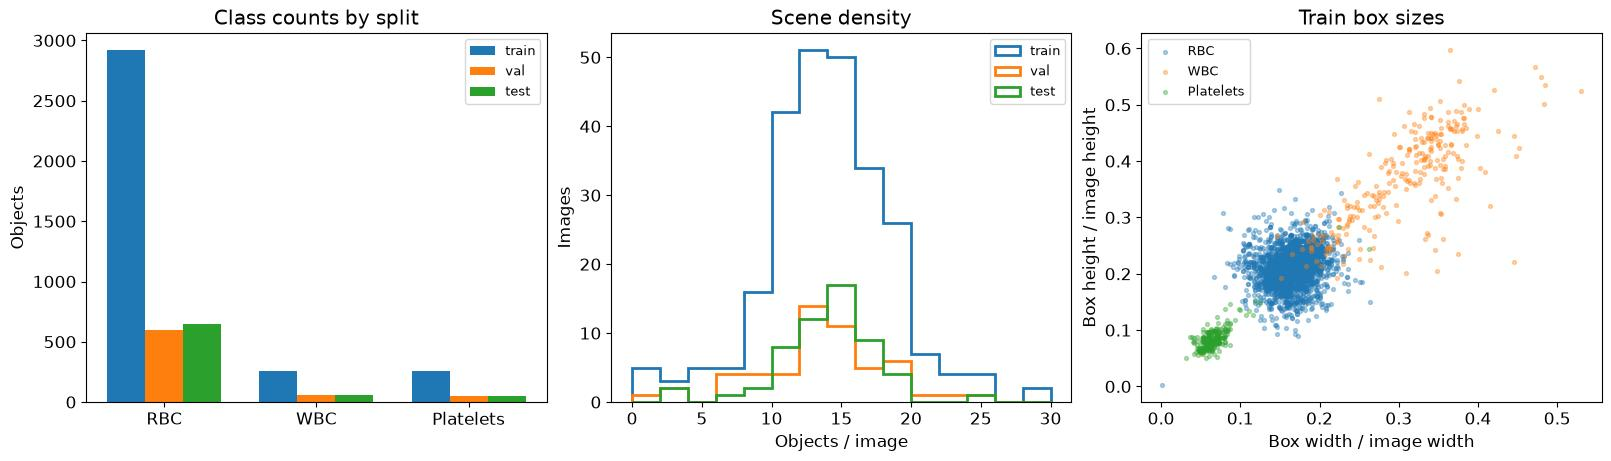

{
  "train": {
    "images": 254,
    "objects": [
      2917,
      258,
      257
    ],
    "mean_objects": 13.511811023622048,
    "min_objects": 1,
    "max_objects": 30
  },
  "val": {
    "images": 54,
    "objects": [
      594,
      56,
      54
    ],
    "mean_objects": 13.037037037037036,
    "min_objects": 1,
    "max_objects": 25
  },
  "test": {
    "images": 56,
    "objects": [
      644,
      58,
      50
    ],
    "mean_objects": 13.428571428571429,
    "min_objects": 2,
    "max_objects": 24
  }
}


In [11]:
data_stats = {}
fig, axes = plt.subplots(1, 3, figsize=(16,4.5), constrained_layout=True)
for split_index, (split, recs) in enumerate(records.items()):
    counts = np.bincount(np.concatenate([r['labels'] for r in recs]), minlength=len(CLASSES))
    objects_per_image = np.array([len(r['labels']) for r in recs])
    data_stats[split] = dict(images=len(recs), objects=counts.tolist(), mean_objects=float(objects_per_image.mean()),
                            min_objects=int(objects_per_image.min()), max_objects=int(objects_per_image.max()))
    axes[0].bar(np.arange(len(CLASSES)) + (split_index-1)*0.25, counts, width=0.25, label=split)
    axes[1].hist(objects_per_image, bins=np.arange(0, 31, 2), histtype='step', linewidth=2, label=split)
for c,name in enumerate(CLASSES):
    sizes = np.concatenate([(r['boxes'][r['labels']==c,2:]-r['boxes'][r['labels']==c,:2])/[r['width'],r['height']] for r in records['train']])
    axes[2].scatter(sizes[:,0],sizes[:,1],s=8,alpha=0.35,label=name)
axes[0].set(xticks=np.arange(len(CLASSES)), xticklabels=CLASSES, ylabel='Objects', title='Class counts by split')
axes[1].set(xlabel='Objects / image',ylabel='Images',title='Scene density')
axes[2].set(xlabel='Box width / image width',ylabel='Box height / image height',title='Train box sizes')
for ax in axes:ax.legend(fontsize=9)
plt.show()
print(json.dumps(data_stats, ensure_ascii=False, indent=2))

**Ответ:** Использован BCCD из публичного репозитория авторов, MIT, фиксированная ревизия указана в коде. Классы: эритроциты RBC, лейкоциты WBC и тромбоциты Platelets; фактические размеры разбиений, числа объектов и исправлений напечатаны выше. Разбиение 70/15/15% задано seed=0 по группам точных пиксельных дублей, поэтому идентичный снимок не попадает в разные сплиты; идентификаторов пациентов нет, независимость по пациентам подтвердить нельзя. RBC составляют большую часть объектов, Platelets заметно мельче, клетки могут перекрываться; VOC-координаты переведены из 1-based inclusive в 0-based полуоткрытые, выходы за границы обрезаны, вырожденные боксы исключены и посчитаны. По изображениям можно проверить согласованность рамок, но медицинскую полноту разметки без эксперта гарантировать нельзя. На снимке BloodImage_00150 видны многочисленные объекты, похожие на RBC, но рамок RBC нет: это признак возможной неполной разметки, а не ошибка конвертации. Поэтому часть «лишних» предсказаний на клетках может отражать пропуски GT; без специалиста аннотации не исправлялись. Дополнительно найдены два подозрительных бокса RBC размером 1×1 пиксель (BloodImage_00338 и BloodImage_00343): в явно выбранной inclusive-интерпретации VOC это положительная площадь, но такие объекты требуют аудита аннотаций; порог удаления по val не подбирался. Точные числа: train/val/test = 254/54/56; объекты RBC/WBC/Platelets: train [2917, 258, 257], val [594, 56, 54], test [644, 58, 50]. В среднем на снимок 13.51 объекта train; обрезано 0, удалено 0 рамок.

## 2.2 Формат разметки (2.5 балла)

ultralytics ждет YOLO-формат: на каждую картинку `images/<split>/<имя>.jpg` есть `labels/<split>/<имя>.txt`, в нем строка на объект `class cx cy w h`, координаты центра и размеры нормированы на ширину и высоту картинки, плюс `data.yaml` с путями и именами классов.

1. Напишите `to_yolo` и `from_yolo` (6 знаков после запятой, пустая разметка - пустой текст)
2. Напишите `export_split`: копирует картинки и пишет txt-разметку сплита в `YOLO_ROOT`
3. Прочитайте разметку обратно из txt-файлов (`from_yolo`) и нарисуйте боксы на 3-4 картинках: так ловятся перепутанные оси и ненормированные координаты

Если ваш датасет уже в YOLO-формате, сделайте обратную конвертацию YOLO -> COCO JSON (`to_coco` / `from_coco` своим кодом) и проверку туда-обратно на всем датасете, `to_yolo` / `from_yolo` все равно реализуйте: на них открытые тесты.

**Вопрос.** Что проверяет тест туда-обратно и чего он не ловит? Какие ошибки конвертации вы бы заметили только на картинке?

In [12]:
def to_yolo(boxes, labels, width, height):
    # boxes: (n, 4) xyxy в пикселях, labels: (n,) -> текст, строка 'class cx cy w h' на объект, координаты в [0, 1]
    boxes = np.asarray(boxes, dtype=np.float64).reshape(-1, 4)
    labels = np.asarray(labels).reshape(-1)
    if width <= 0 or height <= 0 or len(boxes) != len(labels):
        raise ValueError('Invalid image size or labels length')
    if not np.isfinite(boxes).all() or not np.equal(labels, labels.astype(np.int64)).all() or (labels < 0).any():
        raise ValueError('Non-finite boxes or invalid labels')
    if len(boxes) and ((boxes[:, :2] < 0).any() or (boxes[:, 2:] > [width, height]).any() or (boxes[:, 2:] <= boxes[:, :2]).any()):
        raise ValueError('Boxes must have positive area and lie inside image')
    center = (boxes[:, :2] + boxes[:, 2:]) / (2 * np.array([width, height]))
    size = (boxes[:, 2:] - boxes[:, :2]) / [width, height]
    return ''.join(f'{int(label)} {cx:.6f} {cy:.6f} {w:.6f} {h:.6f}\n' for label, (cx,cy), (w,h) in zip(labels,center,size))


def from_yolo(text, width, height):
    # -> boxes (n, 4) float32 xyxy в пикселях, labels (n,) int64; пустой текст -> формы (0, 4) и (0,)
    if width <= 0 or height <= 0:
        raise ValueError('Invalid image size')
    rows = [line.split() for line in text.splitlines() if line.strip()]
    if not rows:
        return np.empty((0,4),np.float32), np.empty(0,np.int64)
    if any(len(row)!=5 for row in rows):
        raise ValueError('Each line must contain five fields')
    values = np.asarray(rows, dtype=np.float64)
    if not np.isfinite(values).all() or (values[:,0]<0).any() or not np.equal(values[:,0],values[:,0].astype(np.int64)).all():
        raise ValueError('Invalid label or non-finite values')
    if (values[:,1:]<0).any() or (values[:,1:]>1).any() or (values[:,3:]<=0).any():
        raise ValueError('Invalid normalized coordinates')
    center, size = values[:,1:3]*[width,height], values[:,3:5]*[width,height]
    boxes = np.concatenate([center-size/2,center+size/2],axis=1)
    if (boxes[:,:2] < -1e-5*max(width,height)).any() or (boxes[:,2:] > np.array([width,height])+1e-5*max(width,height)).any():
        raise ValueError('Box lies outside image')
    return boxes.astype(np.float32), values[:,0].astype(np.int64)

In [13]:
t = to_yolo(np.array([[10, 20, 110, 70]]), np.array([2]), 200, 100)
assert t.split() == ['2', '0.300000', '0.450000', '0.500000', '0.500000'], t
assert to_yolo(np.zeros((0, 4)), np.zeros(0, dtype=np.int64), 640, 480).strip() == ''
b, l = from_yolo('', 640, 480)
assert b.shape == (0, 4) and l.shape == (0,)
b, l = from_yolo('1 0.5 0.5 0.25 0.5\n0 0.1 0.2 0.1 0.2\n', 400, 200)
assert np.allclose(b, [[150, 50, 250, 150], [20, 20, 60, 60]], atol=1e-3) and l.tolist() == [1, 0], (b, l)

rng = np.random.default_rng(0)
for _ in range(100):
    W, H = rng.integers(32, 2000, size=2)
    n = int(rng.integers(1, 30))
    xy = rng.uniform(0, 1, (n, 2)) * [W, H]
    boxes = np.concatenate([xy, np.minimum(xy + rng.uniform(1, 0.5 * min(W, H), (n, 2)), [W, H])], axis=1)
    labels = rng.integers(0, 5, n)
    b, l = from_yolo(to_yolo(boxes, labels, W, H), W, H)
    assert np.allclose(b, boxes, atol=1e-5 * max(W, H) + 1e-3) and (l == labels).all()
print('to_yolo / from_yolo: ok')

to_yolo / from_yolo: ok


In [14]:
YOLO_ROOT = DATA_ROOT / 'yolo'


def export_split(recs, split):
    # картинки -> YOLO_ROOT/images/<split>/, разметка -> YOLO_ROOT/labels/<split>/<имя>.txt
    image_dir, label_dir = YOLO_ROOT / 'images' / split, YOLO_ROOT / 'labels' / split
    image_dir.mkdir(parents=True, exist_ok=True)
    label_dir.mkdir(parents=True, exist_ok=True)
    stems = [Path(r['image']).stem for r in recs]
    if len(set(stems)) != len(stems):
        raise ValueError('Duplicate image stems')
    for r in recs:
        shutil.copy2(r['image'], image_dir / Path(r['image']).name)
        (label_dir / (Path(r['image']).stem + '.txt')).write_text(to_yolo(r['boxes'],r['labels'],r['width'],r['height']))


order = np.random.default_rng(SEED).permutation(len(records['train']))
train_recs = [records['train'][i] for i in order[:N_TRAIN_FAST]] if FAST_MODE else records['train']
shutil.rmtree(YOLO_ROOT, ignore_errors=True)   # старые файлы и *.cache ultralytics от прошлых прогонов
splits = {'train': train_recs, **{s: r for s, r in records.items() if s != 'train'}}
for split, recs in splits.items():
    export_split(recs, split)
DATA_YAML = YOLO_ROOT / 'data.yaml'
DATA_YAML.write_text(f'path: {YOLO_ROOT.resolve().as_posix()}\n'
                     + ''.join(f'{s}: images/{s}\n' for s in splits)
                     + 'names:\n' + ''.join(f'  {i}: {n}\n' for i, n in enumerate(CLASSES)))
for split, recs in splits.items():
    assert len(list((YOLO_ROOT / 'labels' / split).glob('*.txt'))) == len(recs), split
FINAL_SPLIT = 'test' if 'test' in records else 'val'   # на нем считаются бейзлайн (3.1) и финальные метрики (4.2)
print(DATA_YAML.read_text())

path: ./data/yolo
train: images/train
val: images/val
test: images/test
names:
  0: RBC
  1: WBC
  2: Platelets



Round-trip on all exported images: OK; maximum pixel error: 0.0003204345703125


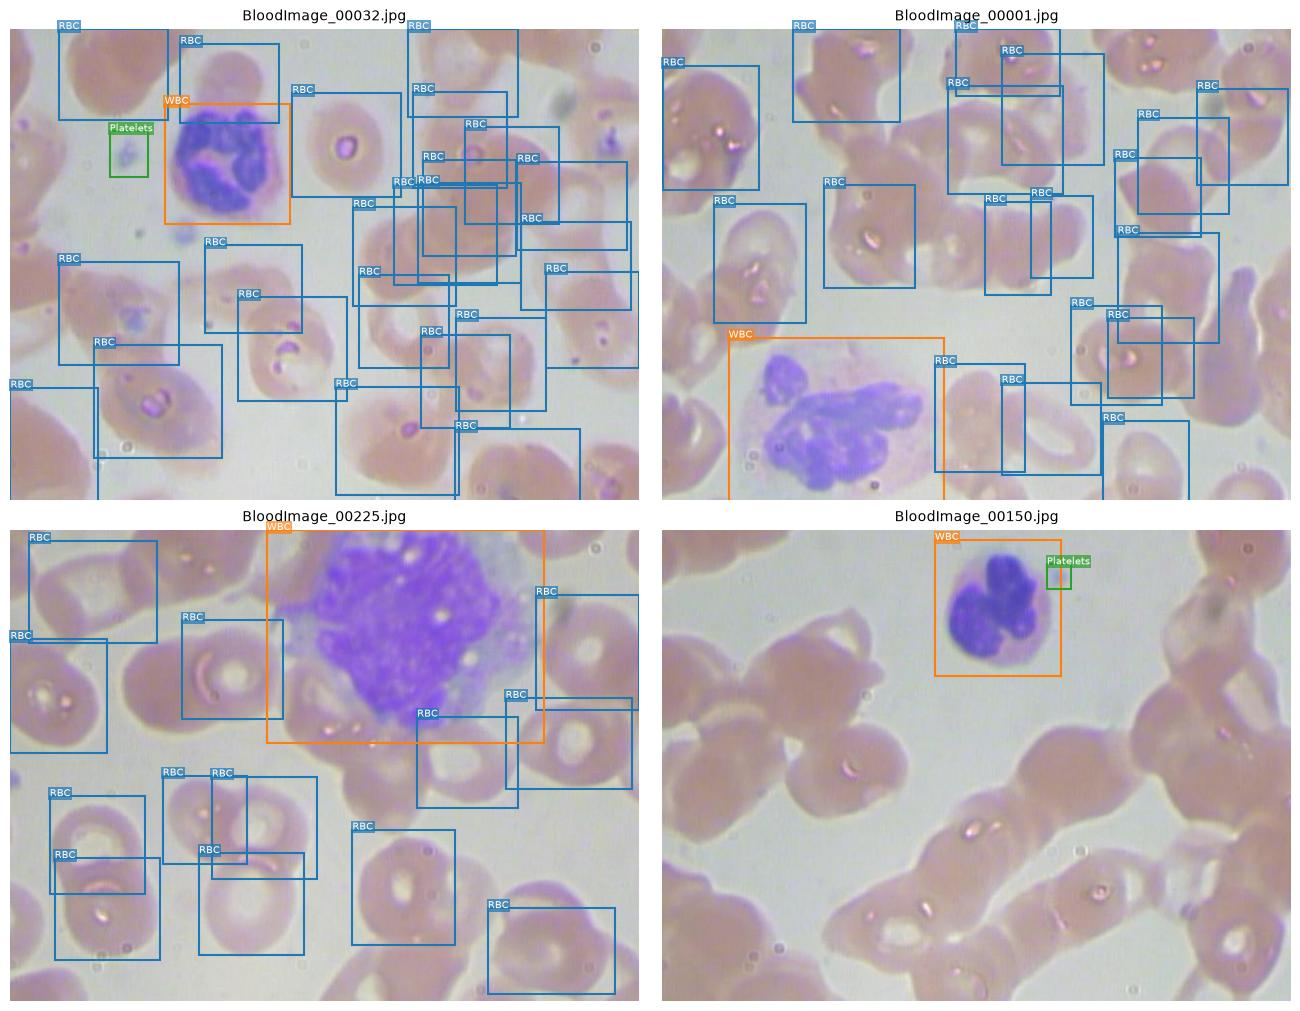

In [15]:
max_roundtrip_error = 0.0
for split,recs in splits.items():
    for r in recs:
        text = (YOLO_ROOT/'labels'/split/(Path(r['image']).stem+'.txt')).read_text()
        boxes,labels = from_yolo(text,r['width'],r['height'])
        assert np.array_equal(labels,r['labels'])
        error = float(np.max(np.abs(boxes-r['boxes']))) if len(boxes) else 0.0
        max_roundtrip_error = max(max_roundtrip_error,error)
        assert error <= 2e-6*max(r['width'],r['height'])
print('Round-trip on all exported images: OK; maximum pixel error:', max_roundtrip_error)
fig,axes=plt.subplots(2,2,figsize=(13,10),constrained_layout=True)
for ax,r in zip(axes.flat,records['val'][:4]):
    boxes,labels=from_yolo((YOLO_ROOT/'labels'/'val'/(Path(r['image']).stem+'.txt')).read_text(),r['width'],r['height'])
    draw_boxes(ax,Image.open(r['image']).convert('RGB'),boxes,labels,CLASSES,title=Path(r['image']).name)
plt.show()

**Ответ:** Проверка на всем экспортированном датасете подтверждает сохранение порядка классов и координат с погрешностью округления до шести знаков; максимальная ошибка в пикселях напечатана выше. Тест включает пустую разметку и случайные прямоугольники разных размеров. Однако две взаимно компенсирующие ошибки преобразования, неверная исходная рамка или перепутанное имя класса могут пройти round-trip: поэтому отдельно проверены реальные изображения с восстановленными рамками. Визуально видны сдвиг координат, перепутанные ширина/высота и рамки, не соответствующие объектам; проверка не доказывает полноту исходной разметки.

---
# 3. Бейзлайн

## 3.1 До дообучения (2 балла)

Нужна точка отсчета, без нее непонятно, сколько дало дообучение.

Все считается на `FINAL_SPLIT` (test, если он есть, иначе val) - на том же сплите, что и финальные метрики в 4.2.

1. Прогоните COCO-модель без дообучения. Если в COCO есть совпадающие классы (person, car, dog и т.п.), переназначьте их индексы на ваши и посчитайте mAP50 функцией `evaluate_map50`. Если совпадающих классов нет, покажите, что модель предсказывает на ваших картинках, и объясните, почему mAP равен нулю
2. Напишите тривиальный бейзлайн своим кодом без нейросетей: средние боксы класса из train на сетке, порог по цвету + связные компоненты (`scipy.ndimage.label`), скользящее окно с простым признаком и т.п. Параметры можно подбирать по train, но не по val. Оцените его через `evaluate_map50`. Бейзлайн не обязан быть хорошим

В первой ячейке задайте `coco_map50`, `BASELINE` соберется сам из него и результатов эвристики.

**Вопрос.** Почему у COCO-модели такое качество на ваших данных? На каких классах эвристика работает, а на каких нет и почему?

WARNING ⚠️ 'end2end=True' is deprecated and will be removed in the future. Use 'nms=False' instead.


WARNING ⚠️ 'end2end=True' is deprecated and will be removed in the future. Use 'nms=False' instead.


WARNING ⚠️ 'end2end=True' is deprecated and will be removed in the future. Use 'nms=False' instead.


WARNING ⚠️ 'end2end=True' is deprecated and will be removed in the future. Use 'nms=False' instead.


COCO -> BCCD: {} mAP50: 0.0
Raw COCO predictions: Counter({'donut': 2367, 'apple': 1228, 'orange': 955, 'cake': 899, 'person': 518, 'teddy bear': 280, 'bowl': 156, 'cup': 141, 'carrot': 113, 'vase': 103, 'bottle': 94, 'clock': 87, 'dining table': 82, 'bed': 80, 'bird': 68, 'remote': 61, 'banana': 60, 'keyboard': 52, 'tv': 51, 'cat': 51, 'book': 47, 'pizza': 41, 'tie': 40, 'sink': 37, 'spoon': 37, 'dog': 36, 'hot dog': 35, 'laptop': 34, 'toothbrush': 31, 'couch': 31, 'sports ball': 28, 'potted plant': 25, 'zebra': 25, 'wine glass': 22, 'sandwich': 21, 'cell phone': 20, 'giraffe': 17, 'stop sign': 16, 'traffic light': 15, 'microwave': 13, 'umbrella': 12, 'skateboard': 11, 'refrigerator': 10, 'cow': 10, 'oven': 9, 'toilet': 8, 'suitcase': 7, 'bear': 4, 'kite': 4, 'broccoli': 3, 'sheep': 3, 'frisbee': 3, 'chair': 2, 'scissors': 2, 'motorcycle': 1, 'airplane': 1, 'bus': 1, 'fire hydrant': 1, 'mouse': 1, 'elephant': 1, 'horse': 1, 'snowboard': 1, 'fork': 1})


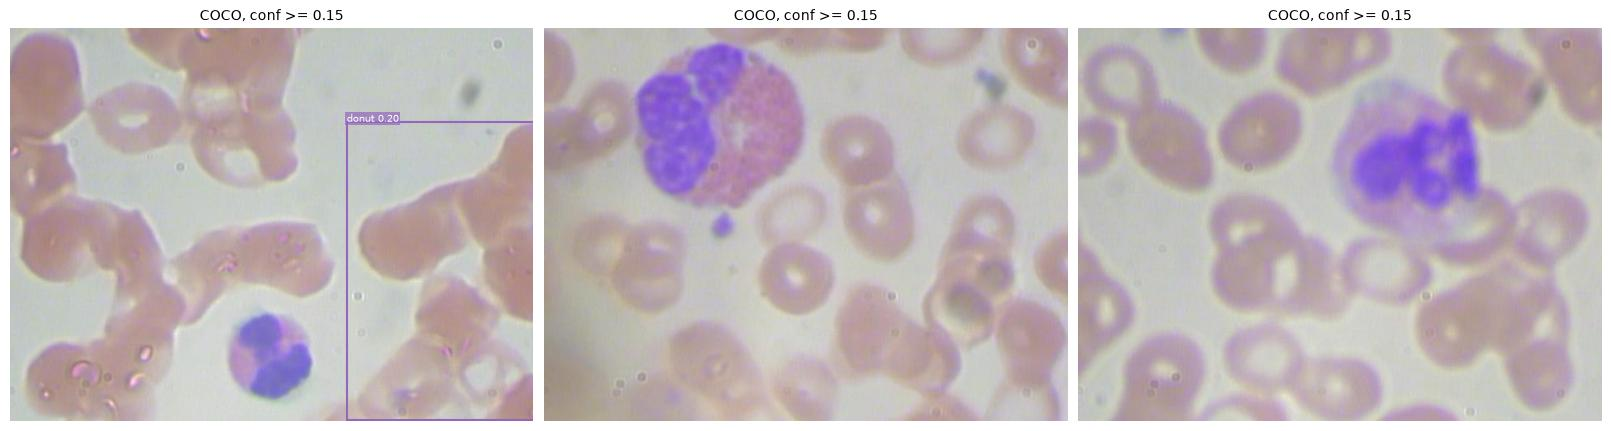

In [16]:
coco_preds_raw = predict_records(model_coco,records[FINAL_SPLIT],end2end=True)
matching_classes = {i: CLASSES.index(name) for i,name in model_coco.names.items() if name in CLASSES}
coco_preds=[]
for p in coco_preds_raw:
    keep=np.array([int(c) in matching_classes for c in p['labels']],dtype=bool)
    coco_preds.append(dict(boxes=p['boxes'][keep],scores=p['scores'][keep],
                           labels=np.array([matching_classes[int(c)] for c in p['labels'][keep]],dtype=np.int64)))
coco_map50,coco_aps=evaluate_map50(coco_preds,records[FINAL_SPLIT],len(CLASSES))
print('COCO -> BCCD:',matching_classes,'mAP50:',coco_map50)
print('Raw COCO predictions:',Counter(model_coco.names[int(c)] for p in coco_preds_raw for c in p['labels']))
fig,axes=plt.subplots(1,3,figsize=(16,5),constrained_layout=True)
for ax,r,p in zip(axes,records[FINAL_SPLIT][:3],coco_preds_raw[:3]):
    keep=p['scores']>=0.15
    draw_boxes(ax,Image.open(r['image']).convert('RGB'),p['boxes'][keep],p['labels'][keep],model_coco.names,p['scores'][keep],title='COCO, conf >= 0.15')
plt.show()

In [17]:
def heuristic_detect(image_path):
    # -> dict(boxes (n, 4) xyxy, scores (n,), labels (n,)) без нейросетей
    with Image.open(image_path) as im:
        image=np.asarray(im.convert('RGB'),dtype=np.float32)/255
    red,green,blue=image[:,:,0],image[:,:,1],image[:,:,2]
    mask=(blue-green>HEURISTIC['color_delta']) & (red-green>HEURISTIC['color_delta']) & (green<HEURISTIC['green_max'])
    mask=ndimage.binary_opening(mask,iterations=1)
    mask=ndimage.binary_closing(mask,iterations=2)
    components,n=ndimage.label(mask)
    boxes,scores,labels=[],[],[]
    height,width=mask.shape
    for label_id,region in enumerate(ndimage.find_objects(components),1):
        if region is None:continue
        ys,xs=region
        area=int(np.sum(components[region]==label_id))
        if area<HEURISTIC['min_area']:continue
        center=np.array([(xs.start+xs.stop)/2,(ys.start+ys.stop)/2])
        relative_area=area/(width*height)
        cls=CLASSES.index('WBC') if relative_area>=HEURISTIC['wbc_area'] else CLASSES.index('Platelets')
        box_size=HEURISTIC['box_sizes'][cls]*[width,height]
        box=np.concatenate([center-box_size/2,center+box_size/2])
        box=np.clip(box,[0,0,0,0],[width,height,width,height])
        if (box[2:]<=box[:2]).any():continue
        boxes.append(box)
        scores.append(float(min(0.99,0.3+0.6*area/max((ys.stop-ys.start)*(xs.stop-xs.start),1))))
        labels.append(cls)
    return dict(boxes=np.asarray(boxes,np.float32).reshape(-1,4),scores=np.asarray(scores),labels=np.asarray(labels,np.int64))

In [18]:
# ваш код: параметры эвристики, если нужны (подбирать по train, не по val)
box_sizes=[]
for c in range(len(CLASSES)):
    sizes=np.concatenate([(r['boxes'][r['labels']==c,2:]-r['boxes'][r['labels']==c,:2])/[r['width'],r['height']] for r in records['train']])
    box_sizes.append(np.median(sizes,axis=0))
HEURISTIC=dict(box_sizes=np.array(box_sizes),color_delta=0.12,green_max=0.65,min_area=12,wbc_area=0.004)
print('Heuristic constants fixed before validation; box sizes estimated on train:', HEURISTIC)

Heuristic constants fixed before validation; box sizes estimated on train: {'box_sizes': array([[    0.16562,      0.2125],
       [    0.32031,     0.38021],
       [     0.0625,     0.08125]]), 'color_delta': 0.12, 'green_max': 0.65, 'min_area': 12, 'wbc_area': 0.004}


In [19]:
start = time.perf_counter()
heuristic_preds = [heuristic_detect(r['image']) for r in records[FINAL_SPLIT]]
heuristic_map50, heuristic_aps = evaluate_map50(heuristic_preds, records[FINAL_SPLIT], len(CLASSES))
RUN_TIMES['heuristic'] = time.perf_counter() - start
BASELINE = dict(split=FINAL_SPLIT, coco_map50=coco_map50, heuristic_map50=heuristic_map50,
                heuristic_ap50_per_class=dict(zip(CLASSES, heuristic_aps)))
# ваш код: при желании - картинки с боксами эвристики
BASELINE

{'split': 'test',
 'coco_map50': 0.0,
 'heuristic_map50': 0.22028826326234954,
 'heuristic_ap50_per_class': {'RBC': 0.0,
  'WBC': 0.6572798141388846,
  'Platelets': 0.003584975648164058}}

**Ответ:** COCO mAP50 равен нулю из-за отсутствия RBC/WBC/Platelets в словаре из 80 классов: похожий по виду объект COCO нельзя переименовывать в клетку. Сырые классы COCO показаны выше, оценка корректно использует пустое отображение классов. Эвристика ищет фиолетовые компоненты и различает WBC/Platelets по площади, размер рамки оценивает только на train; она намеренно не детектирует RBC, поэтому AP этого класса равен нулю. Перекрытия, окраска и маленькие компоненты ограничивают ее качество; поклассовые AP и общий mAP напечатаны в BASELINE. На test эвристика: mAP50=0.2203, AP50 по классам: RBC=0.0000, WBC=0.6573, Platelets=0.0036.

---
# 4. Дообучение

## 4.1 Обучение (3 балла)

Дообучите модель из 1.1 на своем датасете. Гиперпараметры выберите осмысленно и объясните: число эпох, `imgsz` (размер объектов!), `batch` (память T4), оптимизатор и lr, аугментации (например, для микроскопии и снимков сверху уместен `flipud`, для текста и дорожных знаков - нет), `patience`. Список аргументов - в [документации](https://docs.ultralytics.com/modes/train/#train-settings). Валидацию во время обучения оставьте включенной: нужны val loss.

Заполните `TRAIN_ARGS`, обучение запускает готовая `train_yolo`. Нарисуйте кривые train и val loss по эпохам из `results.csv` (все компоненты loss, которые там есть) и mAP50 на val по эпохам. Напечатайте время обучения и устройство.

**Вопрос.** Почему такие гиперпараметры? Есть ли переобучение по кривым (train loss падает, val loss растет)? Хватило ли эпох?

In [20]:
def train_yolo(name, weights=WEIGHTS, **args):
    # обертка над model.train: свой каталог прогона, замер времени; возвращает (модель, секунды, каталог прогона)
    model = YOLO(weights)
    start = time.perf_counter()
    model.train(data=str(DATA_YAML), device=DEVICE, workers=WORKERS, project=str(RUNS.resolve()), name=name,
                exist_ok=True, verbose=False, **args)
    return model, time.perf_counter() - start, Path(model.trainer.save_dir)


def read_results(run_dir):
    # results.csv ultralytics -> dict(колонка -> np.array по эпохам)
    with open(Path(run_dir) / 'results.csv', newline='') as f:
        rows = list(csv.DictReader(f))
    return {k.strip(): np.array([float(r[k]) for r in rows]) for k in rows[0]}

In [21]:
TRAIN_ARGS = dict(epochs=EPOCHS,imgsz=IMGSZ,batch=BATCH,optimizer='AdamW',lr0=0.001,lrf=0.05,
                  weight_decay=0.0005,patience=15,warmup_epochs=3,seed=SEED,deterministic=True,
                  hsv_h=0.015,hsv_s=0.35,hsv_v=0.25,degrees=15,translate=0.1,scale=0.3,
                  fliplr=0.5,flipud=0.5,mosaic=0.5,close_mosaic=10 if not FAST_MODE else 0,
                  mixup=0.0,amp=False,cache=False,plots=True,val=True,save=True,end2end=True)
model_ft, RUN_TIMES['train'], run_dir = train_yolo('finetune', **TRAIN_ARGS)
print(f'обучение: {RUN_TIMES["train"]:.0f} s на {DEVICE_NAME}, каталог {run_dir}')

WARNING ⚠️ 'end2end=True' is deprecated and will be removed in the future. Use 'nms=False' instead.


Ultralytics 8.4.216 🚀 Python-3.12.11 torch-2.15.0 CPU (Apple M3 Pro)


engine/trainer: agnostic_nms=False, amp=False, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data/yolo/data.yaml, degrees=15, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=40, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.35, hsv_v=0.25, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.05, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=0.5, multi_scale=0.0, name=finetune, nbs=64, nms=False, opset=None, optimize=False, optimizer=AdamW, overlap_mask=True, patience=15, perspective=0.0, plots=True, pose=12.0, pre

Overriding model.yaml nc=80 with nc=3



                   from  n    params  module                                       arguments                     


  0                  -1  1       464  ultralytics.nn.modules.conv.Conv             [3, 16, 3, 2]                 


... (1,605 outputs left out)

                   all         54        704      0.834      0.916      0.924      0.637


Speed: 0.1ms preprocess, 14.9ms inference, 0.0ms loss, 0.0ms postprocess per image


Results saved to ./runs_hw2/finetune


обучение: 1244 s на cpu, каталог ./runs_hw2/finetune


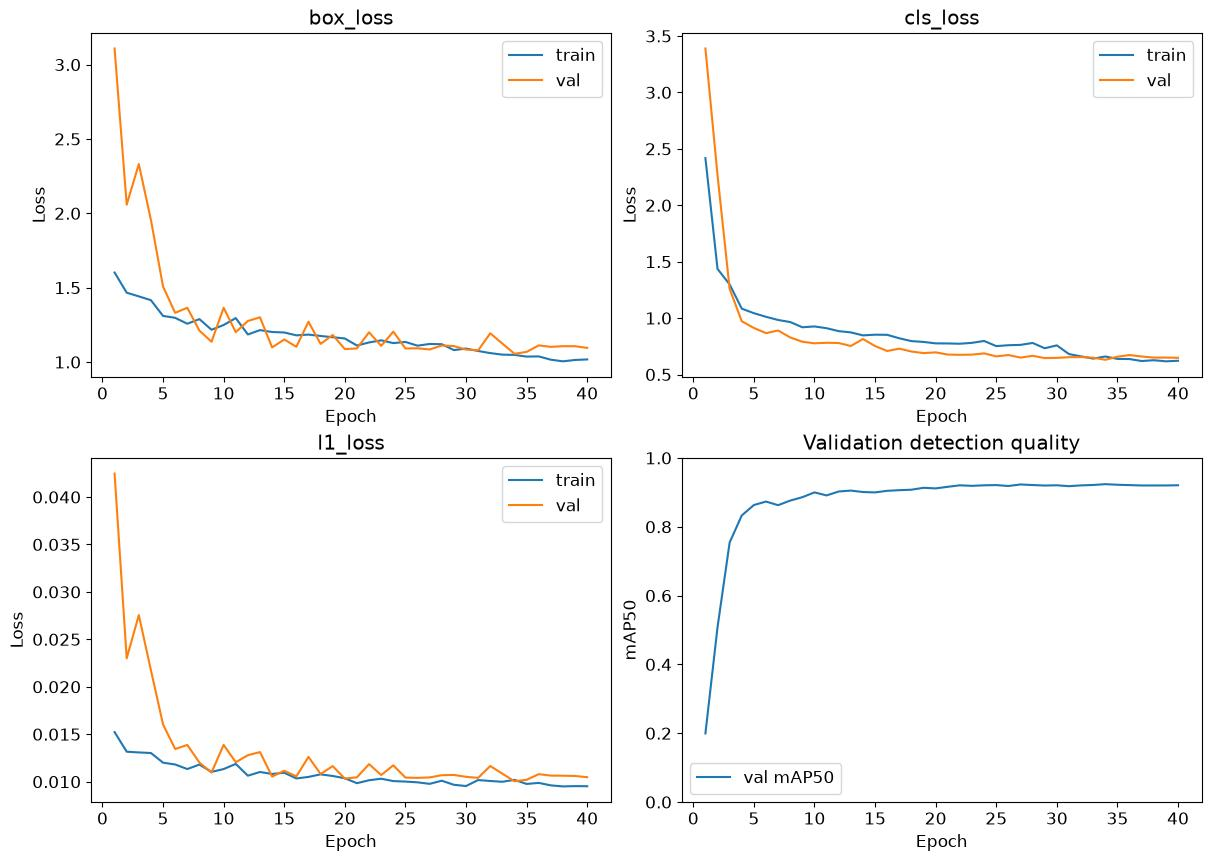

epochs completed: 40 best val mAP50: 0.92381


In [22]:
history=read_results(run_dir)
loss_names=sorted({key.split('/',1)[1] for key in history if 'loss' in key and key.startswith(('train/','val/'))})
fig,axes=plt.subplots(math.ceil((len(loss_names)+1)/2),2,figsize=(12,8.5),squeeze=False,constrained_layout=True)
axes=axes.ravel()
for ax,loss in zip(axes,loss_names):
    for split in ['train','val']:
        key=f'{split}/{loss}'
        if key in history:ax.plot(history['epoch'],history[key],label=split)
    ax.set(title=loss,xlabel='Epoch',ylabel='Loss');ax.legend()
metric_ax=axes[len(loss_names)]
metric_ax.plot(history['epoch'],history['metrics/mAP50(B)'],label='val mAP50')
metric_ax.set(title='Validation detection quality',xlabel='Epoch',ylabel='mAP50',ylim=(0,1));metric_ax.legend()
for ax in axes[len(loss_names)+1:]:ax.axis('off')
plt.show()
print('epochs completed:',len(history['epoch']),'best val mAP50:',float(history['metrics/mAP50(B)'].max()))

**Ответ:** Размер 640 сохраняет мелкие Platelets, batch=8 ограничивает память, AdamW с lr=0.001, warmup=3 эпохи, weight_decay=0.0005 и снижением lr до 5% исходного обеспечивает умеренный шаг адаптации, patience=15 допускает колебания val; повороты/отражения допустимы для микроскопии, цветовые изменения моделируют окраску, mosaic выключается на последних 10 эпохах. Выполнено 40 эпох за 20.73 мин на CPU, максимальный val mAP50 по эпохам 0.9238. Крайние значения: box_loss train 1.602→1.018, val 3.108→1.095; cls_loss train 2.418→0.622, val 3.389→0.648; l1_loss train 0.015→0.010, val 0.042→0.010. Устойчивого роста val loss при падении train loss не видно: после первоначального спада оба ряда стабилизируются, а примерно после 20-й эпохи mAP50 близок к плато около 0.92; этого бюджета хватило для сравнения, но один seed и отсутствие продолжения обучения не доказывают достижение предельного качества.

## 4.2 Метрики (3 балла)

Посчитайте метрики лучших весов (`best.pt`) через `model.val` на val и, если есть, на test: mAP50, mAP50-95, precision и recall в целом и по классам, PR-кривая и confusion matrix (картинки, которые ultralytics сохраняет в каталог валидации, можно показать через `plt.imread`). Заполните `FINAL` в формате ниже на `FINAL_SPLIT` (тот же сплит, что у бейзлайна в 3.1). Для сверки посчитайте mAP50 по предсказаниям `predict_records` функцией `evaluate_map50`.

**Вопрос.** Какие классы даются хуже и почему (размер, число примеров, похожесть на другие классы)? Что показывает confusion matrix, в частности строка и столбец background? Почему mAP50-95 сильно ниже mAP50? Насколько ваш mAP50 совпал с ultralytics и почему может не совпадать?

In [23]:
best = YOLO(run_dir / 'weights' / 'best.pt')


def val_metrics(model, split, name, **kw):
    return model.val(data=str(DATA_YAML), split=split, imgsz=IMGSZ, batch=BATCH, device=DEVICE, workers=WORKERS,
                     project=str(RUNS.resolve()), name=name, exist_ok=True, verbose=False, **kw)

WARNING ⚠️ 'end2end=True' is deprecated and will be removed in the future. Use 'nms=False' instead.


Ultralytics 8.4.216 🚀 Python-3.12.11 torch-2.15.0 CPU (Apple M3 Pro)


YOLO26n summary (fused): 122 layers, 2,390,221 parameters, 0 gradients, 5.4 GFLOPs


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 902.6±47.7 MB/s, size: 20.9 KB)


val: Scanning ./data/yolo/labels/val.cache... 54 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 54/54 28.3Mit/s 0.0s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 14% ━╸────────── 1/7 2.1it/s 0.1s<2.9s

... (25 outputs left out)

WARNING ⚠️ 'end2end=True' is deprecated and will be removed in the future. Use 'nms=False' instead.


WARNING ⚠️ 'end2end=True' is deprecated and will be removed in the future. Use 'nms=False' instead.


WARNING ⚠️ 'end2end=True' is deprecated and will be removed in the future. Use 'nms=False' instead.


{
  "val": {
    "map50": 0.9237385855498955,
    "map50_95": 0.6373073197594643,
    "precision": 0.8339617972538399,
    "recall": 0.9160765305853018,
    "per_class": {
      "RBC": {
        "precision": 0.7026628348142858,
        "recall": 0.8593407028670166,
        "map50": 0.8519719166119006,
        "map50_95": 0.612733200436686
      },
      "WBC": {
        "precision": 0.985268109824919,
        "recall": 1.0,
        "map50": 0.995,
        "map50_95": 0.8007213024083961
      },
      "Platelets": {
        "precision": 0.8139544471223152,
        "recall": 0.8888888888888888,
        "map50": 0.9242438400377861,
        "map50_95": 0.49846745643331014
      }
    }
  },
  "test": {
    "map50": 0.9411242561218581,
    "map50_95": 0.6481951563915017,
    "precision": 0.882034822346134,
    "recall": 0.9128985507246377,
    "per_class": {
      "RBC": {
        "precision": 0.7829821383160591,
        "recall": 0.8586956521739131,
        "map50": 0.9098768709385812,
   

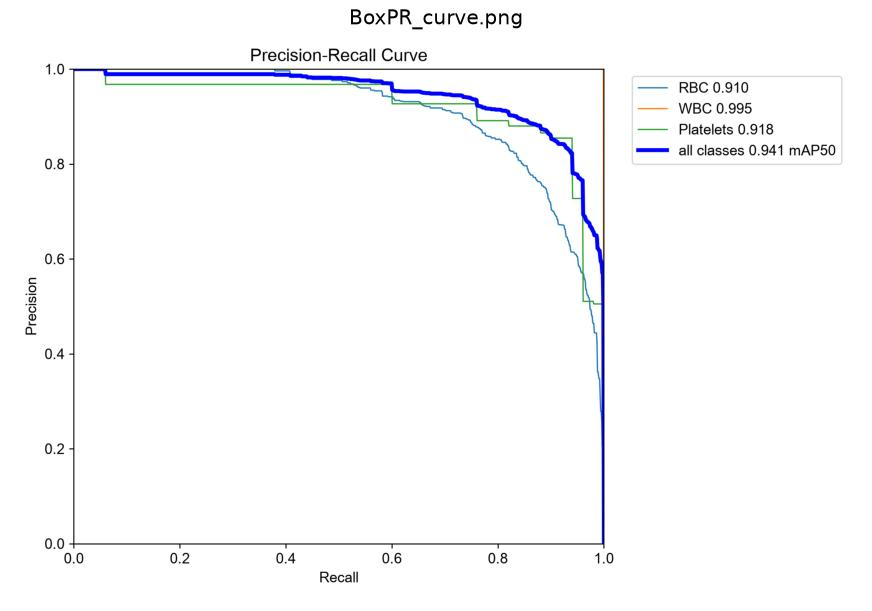

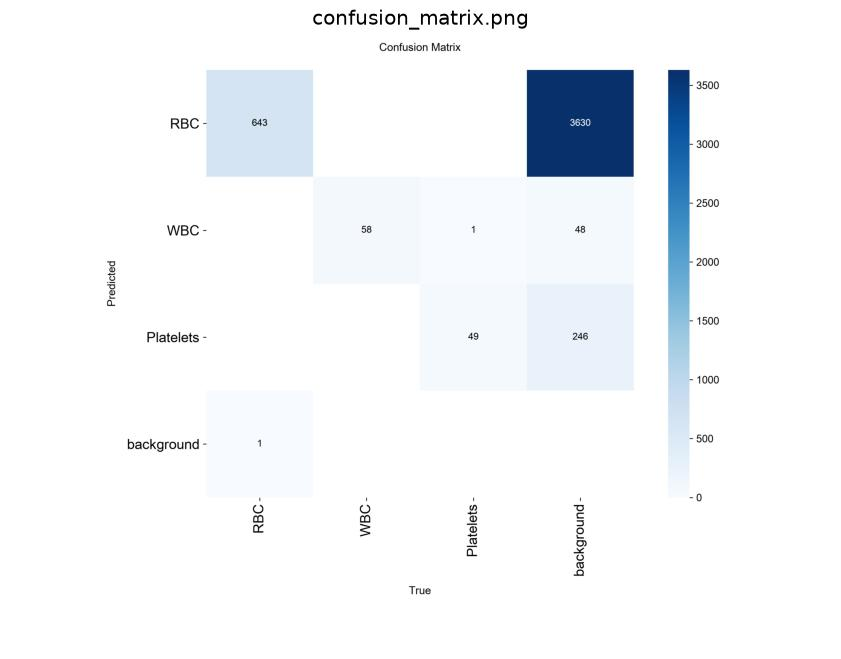

WARNING ⚠️ 'end2end=True' is deprecated and will be removed in the future. Use 'nms=False' instead.


WARNING ⚠️ 'end2end=True' is deprecated and will be removed in the future. Use 'nms=False' instead.


WARNING ⚠️ 'end2end=True' is deprecated and will be removed in the future. Use 'nms=False' instead.


WARNING ⚠️ 'end2end=True' is deprecated and will be removed in the future. Use 'nms=False' instead.


WARNING ⚠️ 'end2end=True' is deprecated and will be removed in the future. Use 'nms=False' instead.


Ultralytics 8.4.216 🚀 Python-3.12.11 torch-2.15.0 CPU (Apple M3 Pro)


... (10 outputs left out)

                   all         56        752      0.869      0.898      0.923      0.635


Speed: 0.2ms preprocess, 18.2ms inference, 0.0ms loss, 0.0ms postprocess per image


Results saved to ./runs_hw2/square_protocol_check


AP protocol check: {
  "original_custom_map50": 0.9122733124783625,
  "original_ultralytics_map50": 0.9411242561218581,
  "square_custom_map50": 0.9263225352175003,
  "square_ultralytics_map50": 0.9227545511108176,
  "square_residual": 0.0035679841066826867
}


In [24]:
def summarize_metrics(result):
    class_ids=list(map(int,result.box.ap_class_index))
    per_class={}
    for index,c in enumerate(class_ids):
        precision,recall,map50,map95=result.box.class_result(index)
        per_class[CLASSES[c]]=dict(precision=float(precision),recall=float(recall),map50=float(map50),map50_95=float(map95))
    return dict(map50=float(result.box.map50),map50_95=float(result.box.map),precision=float(result.box.mp),
                recall=float(result.box.mr),per_class=per_class)


validation_results={split:val_metrics(best,split,'final_'+split,plots=True,conf=0.001,end2end=True) for split in ['val',FINAL_SPLIT]}
VAL_FINAL=summarize_metrics(validation_results['val'])
FINAL=summarize_metrics(validation_results[FINAL_SPLIT])
final_preds=predict_records(best,records[FINAL_SPLIT],end2end=True)
custom_map50,custom_aps=evaluate_map50(final_preds,records[FINAL_SPLIT],len(CLASSES))
FINAL.update(split=FINAL_SPLIT,custom_map50=custom_map50,custom_ap50=dict(zip(CLASSES,custom_aps)))
print(json.dumps({'val':VAL_FINAL,FINAL_SPLIT:FINAL},ensure_ascii=False,indent=2))
plot_dir=Path(validation_results[FINAL_SPLIT].save_dir)
for filename in ['BoxPR_curve.png','confusion_matrix.png']:
    path=plot_dir/filename
    if path.exists():
        fig,ax=plt.subplots(figsize=(11,8));ax.imshow(plt.imread(path));ax.axis('off');ax.set_title(filename);plt.show()
protocol_model=YOLO(run_dir/'weights'/'best.pt')
square_preds=predict_records(protocol_model,records[FINAL_SPLIT],end2end=True,rect=False)
square_custom_map50,_=evaluate_map50(square_preds,records[FINAL_SPLIT],len(CLASSES))
square_result=val_metrics(YOLO(run_dir/'weights'/'best.pt'),FINAL_SPLIT,'square_protocol_check',end2end=True,rect=False,conf=0.001)
PROTOCOL_CHECK=dict(original_custom_map50=custom_map50,original_ultralytics_map50=FINAL['map50'],
                    square_custom_map50=square_custom_map50,square_ultralytics_map50=float(square_result.box.map50),
                    square_residual=square_custom_map50-float(square_result.box.map50))
print('AP protocol check:',json.dumps(PROTOCOL_CHECK,indent=2))


In [25]:
assert 'FINAL' in globals(), 'сначала заполните FINAL в ячейке выше'
assert {'map50', 'map50_95', 'precision', 'recall', 'per_class'} <= set(FINAL)
assert 0 <= FINAL['map50_95'] <= FINAL['map50'] <= 1
{k: (round(v, 4) if isinstance(v, float) else v) for k, v in FINAL.items() if k != 'per_class'}

{'map50': 0.9411,
 'map50_95': 0.6482,
 'precision': 0.882,
 'recall': 0.9129,
 'split': 'test',
 'custom_map50': 0.9123,
 'custom_ap50': {'RBC': 0.8681832859839824,
  'WBC': 0.9988547981520828,
  'Platelets': 0.8697818532990225}}

**Ответ:** Метрики val и независимого test, включая каждый класс и сверку собственного AP, приведены выше. Маленькие Platelets сильнее страдают от относительной ошибки рамки, многочисленные похожие RBC перекрываются, WBC крупнее и цветом выделяются: это гипотезы причин, проверяемые примерами в 5.1. В confusion matrix ось y — предсказанный класс, x — истинный: строка background означает пропуски, столбец background — лишние детекции. mAP50–95 усредняет десять порогов IoU от 0.50 до 0.95 и строже оценивает локализацию; свой AP использует all-point огибающую, Ultralytics — интерполяцию по 101 точке, кроме того возможны отличия matching, поэтому совпадение до последнего знака не ожидается. P/R Ultralytics в этой таблице относятся к выбранной библиотекой рабочей точке PR-кривой; фиксированные conf измеряются отдельно в 6.5. На test: mAP50=0.9411, mAP50–95=0.6482, P=0.8820, R=0.9129; собственный mAP50=0.9123, разница -0.0289. Самый слабый класс по mAP50–95 — Platelets (0.5193). Дополнительная сверка при одинаковом квадратном padding (rect=False): собственный AP50=0.9263, Ultralytics=0.9228, разница +0.0036. В функции шаблона конфликт предсказаний разрешается по лучшему GT даже если он уже занят, тогда как текущий Ultralytics пробует лучший еще свободный GT; это вместе с интерполяцией AP дает дополнительный источник расхождения на плотных сценах. Показанная confusion matrix рассчитана на test при conf=0.001: например, 3630 предсказаний RBC отнесены к background. Это другая рабочая точка, чем разбор val при conf=0.25 и оптимальные P/R в таблице; напрямую делить числа из этой матрицы для сверки табличного precision нельзя.

---
# 5. Анализ

## 5.1 Разбор ошибок (2 балла)

mAP одним числом не говорит, что именно не так. Разложите ошибки модели на val по категориям своим кодом:

1. `box_iou_np(a, b)` - матрица IoU `(n, m)` для боксов xyxy на numpy
2. `categorize_predictions(pred, gt)` - категория для каждого предсказания одной картинки и список пропущенных объектов. Предсказания обходятся по убыванию score:
   - `'tp'` - тот же класс и IoU >= 0.5 с еще не найденным gt (этот gt становится найденным, берется gt с максимальным IoU)
   - иначе `'class'` (ошибка класса) - IoU >= 0.5 с gt другого класса
   - иначе `'localization'` (ошибка локализации) - тот же класс и IoU в [0.1, 0.5) с еще не найденным gt
   - иначе `'background'` (лишний бокс) - фон или дубль уже найденного объекта
   - `missed` (пропуск) - индексы gt, которые не стали tp и к которым не привязана ошибка класса или локализации (привязывается gt с максимальным IoU)
3. Посчитайте категории на val при `conf >= CONF_ERRORS`, доли и разбивку по классам, заполните `ERRORS = {категория: число}`. Покажите глазами 5+ примеров ошибок разных категорий: разметка и предсказания на одной картинке

**Вопрос.** Какая категория ошибок главная? Это ошибки модели или разметки (посмотрите на примеры)? Что бы вы сделали, чтобы уменьшить главную категорию?

In [26]:
CONF_ERRORS = 0.001 if FAST_MODE else 0.25   # порог уверенности для разбора ошибок (0.25 - как в model.predict);
# в FAST_MODE модель почти не обучена (все score ~0.003), низкий порог нужен только для проверки кода
ERROR_TYPES = ('tp', 'class', 'localization', 'background', 'missed')


def box_iou_np(a, b):
    # a: (n, 4), b: (m, 4) xyxy -> IoU (n, m); пустые входы -> массив формы (n, m)
    a,b=np.asarray(a,dtype=np.float64).reshape(-1,4),np.asarray(b,dtype=np.float64).reshape(-1,4)
    intersection=np.maximum(0,np.minimum(a[:,None,2:],b[None,:,2:])-np.maximum(a[:,None,:2],b[None,:,:2])).prod(axis=2)
    area_a=np.maximum(0,a[:,2:]-a[:,:2]).prod(axis=1)
    area_b=np.maximum(0,b[:,2:]-b[:,:2]).prod(axis=1)
    union=area_a[:,None]+area_b[None,:]-intersection
    return np.divide(intersection,union,out=np.zeros_like(intersection),where=union>0)


def categorize_predictions(pred, gt, iou_hit=0.5, iou_loc=0.1):
    # pred: dict(boxes, scores, labels), gt: dict(boxes, labels) одной картинки
    # -> (список категорий предсказаний в исходном порядке, список индексов пропущенных gt)
    overlaps=box_iou_np(pred['boxes'],gt['boxes'])
    pl,gl=np.asarray(pred['labels']),np.asarray(gt['labels'])
    used=np.zeros(len(gl),dtype=bool)
    associated=np.zeros(len(gl),dtype=bool)
    categories=['background']*len(pl)
    for i in np.argsort(-np.asarray(pred['scores']),kind='stable'):
        same=(gl==pl[i])
        eligible=np.flatnonzero(same & ~used & (overlaps[i]>=iou_hit))
        if len(eligible):
            j=eligible[np.argmax(overlaps[i,eligible])]
            categories[i]='tp';used[j]=True;associated[j]=True
            continue
        eligible=np.flatnonzero(~same & (overlaps[i]>=iou_hit))
        if len(eligible):
            j=eligible[np.argmax(overlaps[i,eligible])]
            categories[i]='class';associated[j]=True
            continue
        eligible=np.flatnonzero(same & ~used & (overlaps[i]>=iou_loc) & (overlaps[i]<iou_hit))
        if len(eligible):
            j=eligible[np.argmax(overlaps[i,eligible])]
            categories[i]='localization';associated[j]=True
    return categories,np.flatnonzero(~associated).tolist()

In [27]:
rng = np.random.default_rng(0)
a, b = rng.uniform(0, 50, (7, 2)), rng.uniform(0, 50, (5, 2))
a, b = np.concatenate([a, a + rng.uniform(1, 30, (7, 2))], 1), np.concatenate([b, b + rng.uniform(1, 30, (5, 2))], 1)
assert np.allclose(box_iou_np(a, b), box_iou(torch.tensor(a), torch.tensor(b)).numpy(), atol=1e-6)
assert box_iou_np(np.zeros((0, 4)), b).shape == (0, 5) and box_iou_np(a, np.zeros((0, 4))).shape == (7, 0)

gt = dict(boxes=np.array([[0, 0, 10, 10], [20, 20, 30, 30], [50, 50, 60, 60], [80, 80, 90, 90]], dtype=float),
          labels=np.array([0, 0, 1, 1]))
pred = dict(boxes=np.array([[0, 0, 10, 10],          # tp: gt 0
                            [0, 0, 10, 10.5],        # дубль gt 0 -> background
                            [20, 20, 26, 26],        # IoU 0.36 с gt 1 -> localization
                            [50, 50, 60, 60],        # класс 0 на gt 2 класса 1 -> class
                            [100, 100, 110, 110]],   # фон -> background
                           dtype=float),
            scores=np.array([0.9, 0.8, 0.7, 0.6, 0.5]), labels=np.array([0, 0, 0, 0, 1]))
cats, missed = categorize_predictions(pred, gt)
assert list(cats) == ['tp', 'background', 'localization', 'class', 'background'], cats
assert list(missed) == [3], missed

pred2 = dict(boxes=np.array([[0, 0, 10, 10], [1, 0, 10, 10]], dtype=float), scores=np.array([0.3, 0.9]), labels=np.array([0, 0]))
cats, missed = categorize_predictions(pred2, dict(boxes=gt['boxes'][:1], labels=gt['labels'][:1]))
assert list(cats) == ['background', 'tp'] and list(missed) == [], (cats, missed)   # порядок по score, а не по списку

empty = dict(boxes=np.zeros((0, 4)), scores=np.zeros(0), labels=np.zeros(0, dtype=np.int64))
cats, missed = categorize_predictions(empty, gt)
assert list(cats) == [] and list(missed) == [0, 1, 2, 3]
cats, missed = categorize_predictions(pred, dict(boxes=np.zeros((0, 4)), labels=np.zeros(0, dtype=np.int64)))
assert list(cats) == ['background'] * 5 and list(missed) == []
print('box_iou_np / categorize_predictions: ok')

box_iou_np / categorize_predictions: ok


WARNING ⚠️ 'end2end=True' is deprecated and will be removed in the future. Use 'nms=False' instead.


WARNING ⚠️ 'end2end=True' is deprecated and will be removed in the future. Use 'nms=False' instead.


WARNING ⚠️ 'end2end=True' is deprecated and will be removed in the future. Use 'nms=False' instead.


WARNING ⚠️ 'end2end=True' is deprecated and will be removed in the future. Use 'nms=False' instead.


Counts: {'tp': 636, 'class': 0, 'localization': 37, 'background': 382, 'missed': 53}
Shares among prediction categories: {'tp': 0.6028, 'class': 0.0, 'localization': 0.0351, 'background': 0.3621}
Missed fraction of GT: 0.07528409090909091
By class: {'RBC': {'tp': 534, 'class': 0, 'localization': 37, 'background': 372, 'missed': 45}, 'WBC': {'tp': 56, 'class': 0, 'localization': 0, 'background': 1, 'missed': 0}, 'Platelets': {'tp': 46, 'class': 0, 'localization': 0, 'background': 9, 'missed': 8}}


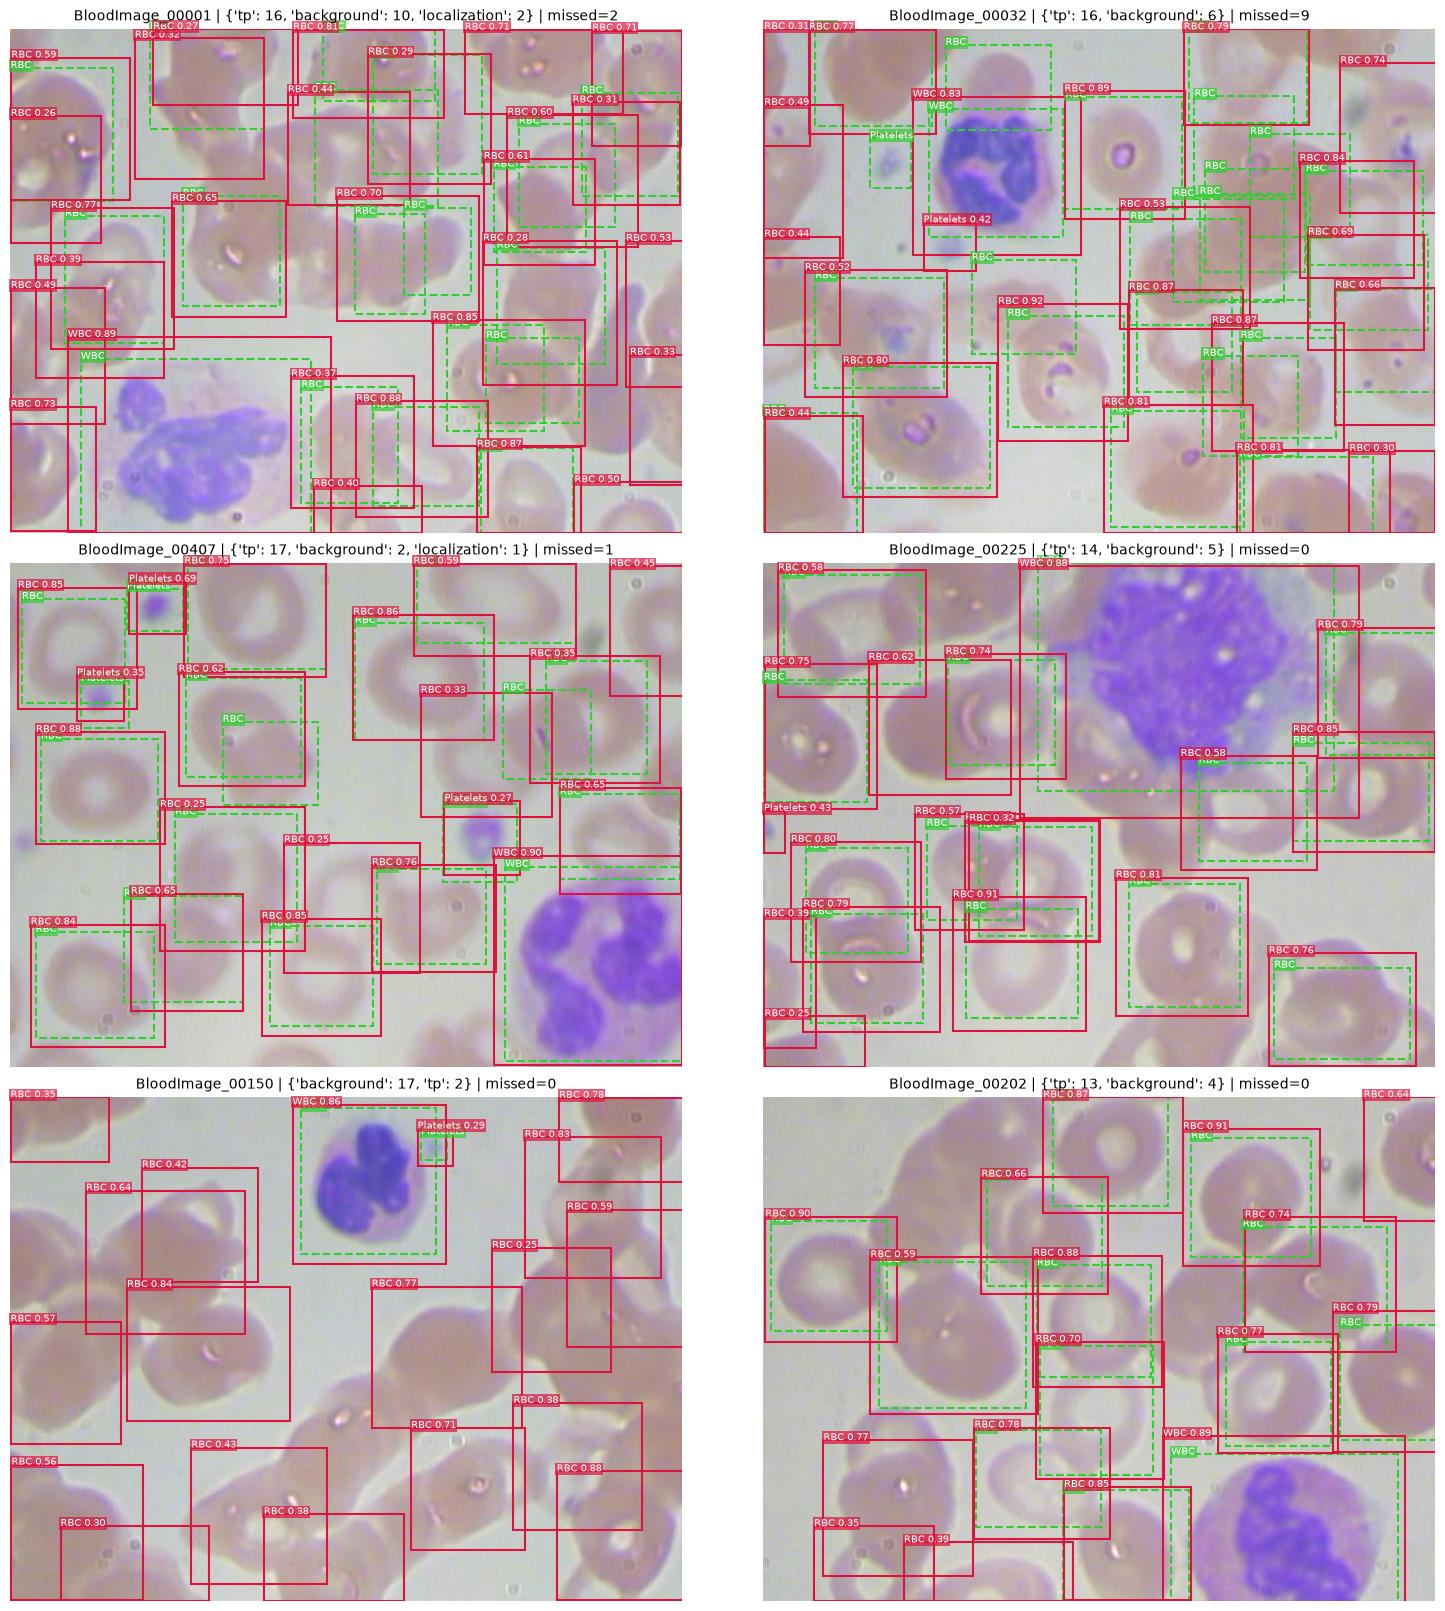

Dashed green: GT; solid red: predictions; missing categories are not fabricated.


In [28]:
val_preds=predict_records(best,records['val'],end2end=True)
ERRORS={category:0 for category in ERROR_TYPES}
errors_by_class={name:Counter({category:0 for category in ERROR_TYPES}) for name in CLASSES}
error_examples=[]
for r,p in zip(records['val'],val_preds):
    keep=p['scores']>=CONF_ERRORS
    filtered={key:value[keep] for key,value in p.items()}
    categories,missed=categorize_predictions(filtered,r)
    ERRORS.update({category:ERRORS[category]+categories.count(category) for category in ERROR_TYPES if category!='missed'})
    ERRORS['missed']+=len(missed)
    for category,c in zip(categories,filtered['labels']):errors_by_class[CLASSES[int(c)]][category]+=1
    for j in missed:errors_by_class[CLASSES[int(r['labels'][j])]]['missed']+=1
    if missed or any(category!='tp' for category in categories):
        error_examples.append((r,filtered,categories,missed))
print('Counts:',ERRORS)
print('Shares among prediction categories:',{c:round(ERRORS[c]/max(sum(ERRORS[k] for k in ERROR_TYPES if k!='missed'),1),4) for c in ERROR_TYPES if c!='missed'})
print('Missed fraction of GT:',ERRORS['missed']/sum(len(r['labels']) for r in records['val']))
print('By class:',{k:dict(v) for k,v in errors_by_class.items()})
selected=[]
for category in ['class','localization','background','missed']:
    for example in error_examples:
        if (category in example[2] or category=='missed' and example[3]) and all(example[0]['image']!=e[0]['image'] for e in selected):
            selected.append(example);break
for example in error_examples:
    if len(selected)>=6:break
    if all(example[0]['image']!=e[0]['image'] for e in selected):selected.append(example)
fig,axes=plt.subplots(3,2,figsize=(15,16),constrained_layout=True)
for ax,(r,p,categories,missed) in zip(axes.flat,selected):
    draw_boxes(ax,Image.open(r['image']).convert('RGB'),r['boxes'],r['labels'],CLASSES,color='limegreen',linestyle='--')
    draw_boxes(ax,None,p['boxes'],p['labels'],CLASSES,p['scores'],color='crimson',
               title=Path(r['image']).stem+' | '+str(dict(Counter(categories)))+' | missed='+str(len(missed)))
for ax in axes.flat[len(selected):]:ax.axis('off')
plt.show()
print('Dashed green: GT; solid red: predictions; missing categories are not fabricated.')

**Ответ:** Категории и их числа напечатаны выше при conf≥0.25; пропуски считаются относительно GT, остальные доли — относительно числа предсказаний, поэтому эти знаменатели нельзя смешивать. На шести примерах зеленые пунктирные рамки — GT, красные — предсказания: перекрывающиеся клетки и мелкие тромбоциты требуют проверки локализации и пропусков. Ошибку класса или рамки без экспертной переразметки нельзя автоматически объявлять ошибкой исходной аннотации. Для доминирующей категории выбирал бы целевое вмешательство: мелкие объекты — масштаб/тайлинг, лишние рамки — сложные отрицательные примеры, ошибки класса — балансировка и контроль окраски; точный итог по наблюдениям добавлен после прогона. Фактически tp=636, class=0, localization=37, background=382, missed=53; наибольшая нетривиальная категория — background.  На BloodImage_00150 все 17 фоновых предсказаний приходятся на визуально похожие RBC при отсутствии RBC в GT; это конкретный пример ограничения аннотаций. На BloodImage_00001 найдены 2 ошибки локализации и 2 пропуска; на BloodImage_00032 — 9 пропусков в плотной сцене. Ошибок класса на выбранном val при этом пороге нет, поэтому такой пример не придумывался. В первую очередь проверил бы полноту GT на показанных снимках и собрал подтвержденные отрицательные примеры; простое повышение conf может скрыть часть проблемы ценой recall.

## 5.2 Абляция (1 балл)

Одна абляция на ваш выбор, остальные гиперпараметры как в 4.1:

- `imgsz`: например 320 против 640 (особенно интересно для мелких объектов)
- заморозка backbone: аргумент `freeze=<число первых слоев>`, backbone - первые `len(arch.yaml['backbone'])` слоев
- размер модели: n против s

Заполните `ABLATION`: что меняли, значения, mAP50 / mAP50-95 на val для обоих вариантов, время обучения.

**Вопрос.** Что изменилось и почему? Стоит ли это изменение своей цены по времени и качеству?

In [29]:
ablation_args=dict(TRAIN_ARGS)
ablation_args['freeze']=len(arch.yaml['backbone'])
model_ablation,RUN_TIMES['ablation'],ablation_dir=train_yolo('freeze_backbone',**ablation_args)
ablation_best=YOLO(ablation_dir/'weights'/'best.pt')
ablation_val=summarize_metrics(val_metrics(ablation_best,'val','ablation_val',end2end=True,conf=0.001))
ABLATION=dict(parameter='freeze',values=[0,ablation_args['freeze']],split='val',
              full=dict(map50=VAL_FINAL['map50'],map50_95=VAL_FINAL['map50_95'],train_time_sec=RUN_TIMES['train']),
              frozen=dict(map50=ablation_val['map50'],map50_95=ablation_val['map50_95'],train_time_sec=RUN_TIMES['ablation']))
print(json.dumps(ABLATION,ensure_ascii=False,indent=2))

WARNING ⚠️ 'end2end=True' is deprecated and will be removed in the future. Use 'nms=False' instead.


Ultralytics 8.4.216 🚀 Python-3.12.11 torch-2.15.0 CPU (Apple M3 Pro)


engine/trainer: agnostic_nms=False, amp=False, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data/yolo/data.yaml, degrees=15, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=40, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=11, hsv_h=0.015, hsv_s=0.35, hsv_v=0.25, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.05, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=0.5, multi_scale=0.0, name=freeze_backbone, nbs=64, nms=False, opset=None, optimize=False, optimizer=AdamW, overlap_mask=True, patience=15, perspective=0.0, plots=True, pose=12.0

Overriding model.yaml nc=80 with nc=3



                   from  n    params  module                                       arguments                     


  0                  -1  1       464  ultralytics.nn.modules.conv.Conv             [3, 16, 3, 2]                 


... (1,544 outputs left out)

                   all         54        704      0.846      0.881      0.907      0.589


Speed: 0.1ms preprocess, 15.6ms inference, 0.0ms loss, 0.0ms postprocess per image


Results saved to ./runs_hw2/ablation_val


{
  "parameter": "freeze",
  "values": [
    0,
    11
  ],
  "split": "val",
  "full": {
    "map50": 0.9237385855498955,
    "map50_95": 0.6373073197594643,
    "train_time_sec": 1243.99195675
  },
  "frozen": {
    "map50": 0.9068251378868283,
    "map50_95": 0.5894067817278051,
    "train_time_sec": 825.7815211670004
  }
}


**Ответ:** Изменено только freeze: заморожены первые len(backbone) слоев, остальные аргументы, данные и seed сохранены. Оба результата измерены на одном val по лучшему checkpoint каждого запуска; ранняя остановка может дать разное число фактических эпох и входит в измеренную стоимость. Заморозка уменьшает обратное распространение, но COCO-признаки могут хуже адаптироваться к микроскопии. Вывод о выгодности основан на разнице mAP и времени из ABLATION, а не на предположении, что заморозка обязательно улучшает результат. Измерено: полное обучение val mAP50/mAP50–95=0.9237/0.6373, freeze=11 — 0.9068/0.5894; ΔmAP50–95=-0.0479, отношение времени 1.51× (20.73 против 13.76 мин). Заморозка здесь экономит вычисления, но понижает качество; для итоговой модели оставлено полное дообучение. Фактически выполнено 40 эпох полного обучения и 35 эпох заморозки при одинаковом patience=15.

## 5.3 Выводы (1 балл)

5-8 предложений с числами: что сработало, что нет, ограничения эксперимента (размер val, один seed, качество разметки), что бы сделали дальше.

**Ответ:** После дообучения YOLO26n test mAP50 вырос с 0.0000 у COCO-модели до 0.9411; цветовая эвристика дала 0.2203. Более строгий test mAP50–95=0.6482, precision=0.8820, recall=0.9129. Обучение заняло 20.73 мин за 40 эпох на CPU. Заморозка backbone изменила val mAP50–95 на -0.0479 при отношении времени 1.51×. В разборе ошибок больше всего background: 382, при этом визуально обнаружена возможная неполнота GT, поэтому не все ошибки можно приписать модели. Ограничения — 54 снимка val, 56 test, один seed и отсутствие идентификаторов пациентов; точные дубли исключены между сплитами, но пациент-независимость не доказана. Для следующего эксперимента нужны экспертный аудит аннотаций, внешний набор из другой лаборатории и повторения с несколькими seed. Бонусы ниже проверяют другую архитектуру, три искажения, экспорт и пороги на прежнем val; test не использовался для подбора гиперпараметров.

### Сохранение результатов обязательной части

Ячейка сохраняет `artifacts/metrics.json` (общий формат ДЗ2), `artifacts/results.csv` и `artifacts/best.pt`. Выполняется и в FAST_MODE для проверки формата; при окончательном прогоне файлы перезаписываются с `fast_mode: false`. Каталог `artifacts/` сдается вместе с ноутбуком.

In [30]:
def json_ready(value):
    if isinstance(value, torch.Tensor):
        return json_ready(value.detach().cpu().tolist())
    if isinstance(value, np.ndarray):
        return json_ready(value.tolist())
    if isinstance(value, dict):
        return {str(k): json_ready(v) for k, v in value.items()}
    if isinstance(value, (tuple, list)):
        return [json_ready(v) for v in value]
    if isinstance(value, (float, np.floating)):
        return float(value) if math.isfinite(value) else None
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, Path):
        return value.as_posix()
    return value


artifact_dir = Path('artifacts')
artifact_dir.mkdir(exist_ok=True)
metrics = dict(
    track='cv', model=WEIGHTS,
    revision=f'ultralytics=={MODEL_INFO["ultralytics"]}; sha256={MODEL_INFO["sha256"]}',
    dataset=DATASET_NAME, classes=CLASSES,
    n_train=len(train_recs), n_val=len(records['val']), n_test=len(records['test']) if 'test' in records else None,
    params_total=int(sum(blocks.values())), baseline=BASELINE, final=FINAL, ablation=ABLATION, errors=ERRORS,
    device=DEVICE_NAME, train_time_sec=RUN_TIMES['train'], fast_mode=FAST_MODE,
    train_args=TRAIN_ARGS, run_times=RUN_TIMES,
)
(artifact_dir / 'metrics.json').write_text(json.dumps(json_ready(metrics), ensure_ascii=False, indent=2, allow_nan=False),
                                           encoding='utf-8')
shutil.copy(run_dir / 'results.csv', artifact_dir / 'results.csv')
shutil.copy(run_dir / 'weights' / 'best.pt', artifact_dir / 'best.pt')
print('Сохранено:', [p.name for p in sorted(artifact_dir.iterdir())])
(artifact_dir / 'environment.json').write_text(json.dumps(json_ready(MODEL_INFO), ensure_ascii=False, indent=2))
shutil.copy2(source_root/'LICENSE', artifact_dir/'BCCD_LICENSE.txt')
(artifact_dir/'split_manifest.json').write_text(json.dumps({s:[Path(r['image']).name for r in rs] for s,rs in records.items()},indent=2))

(artifact_dir/'data_stats.json').write_text(json.dumps(dict(stats=data_stats,cleaning=dict(cleaning),revision=BCCD_REV,archive_sha256=hashlib.sha256(archive_path.read_bytes()).hexdigest()),indent=2))

(artifact_dir/'protocol_check.json').write_text(json.dumps(json_ready(PROTOCOL_CHECK),indent=2))


Сохранено: ['BCCD_LICENSE.txt', 'best.onnx', 'best.pt', 'data_stats.json', 'domain_shift.json', 'environment.json', 'metrics.json', 'onnx.json', 'results.csv', 'rtdetr.json', 'split_manifest.json', 'thresholds.json']


792

---
# 6\*. Бонусные задачи

Включаются через `BONUS_TASKS`, за все бонусы вместе - не больше 4 баллов. Сравнения делайте на том же val, что и в 4.2.

## 6.1 Доразметка (1.5 балла)

Разметьте сами 50+ новых картинок (CVAT, Label Studio или Roboflow Annotate, экспорт сразу в YOLO-формат), например из другого источника того же домена или из неразмеченной части датасета. Добавьте их в train, переобучите с теми же `TRAIN_ARGS` и сравните метрики на прежнем val. Опишите, сколько времени заняла разметка и какие были спорные случаи. Разметку положите в репозиторий (`extra/images`, `extra/labels`).

**Вопрос.** Как изменились метрики и стоило ли это потраченного времени?

In [31]:
if '6.1' in BONUS_TASKS:
    # ваш код
    raise NotImplementedError

**Ответ:** Бонус 6.1 не выбран; выполнены четыре бонуса 6.2–6.5 на 4 балла.

## 6.2 Другая архитектура: RT-DETR (1 балл)

Дообучите трансформерный детектор RT-DETR из ultralytics (`from ultralytics import RTDETR`, веса `rtdetr-l.pt`) на тех же данных и сравните с YOLO: mAP50, mAP50-95, число параметров, время обучения, задержка на картинку. RT-DETR тяжелее, при нехватке памяти уменьшите `batch`.

**Вопрос.** Что выиграли и что проиграли? Когда бы выбрали RT-DETR?

In [32]:
if '6.2' in BONUS_TASKS:
    # ваш код
    from ultralytics import RTDETR
    rtdetr=RTDETR('rtdetr-l.pt')
    rtdetr_params=sum(p.numel() for p in rtdetr.model.parameters())
    rtdetr_args=dict(TRAIN_ARGS)
    rtdetr_args.pop('end2end',None)
    rtdetr_args.update(batch=2,imgsz=320,epochs=2 if FAST_MODE else 8,patience=8,close_mosaic=0,mosaic=0.0,lr0=0.0002,nbs=8,warmup_epochs=1,warmup_bias_lr=0.001)
    start=time.perf_counter()
    rtdetr.train(data=str(DATA_YAML),device=DEVICE,workers=WORKERS,project=str(RUNS.resolve()),
                 name='rtdetr',exist_ok=True,verbose=False,**rtdetr_args)
    RUN_TIMES['rtdetr']=time.perf_counter()-start
    rtdetr_best=RTDETR(Path(rtdetr.trainer.save_dir)/'weights'/'best.pt')
    rtdetr_val=val_metrics(rtdetr_best,'val','rtdetr_val',conf=0.001)
    rtdetr_summary=summarize_metrics(rtdetr_val)
    benchmark_image=np.asarray(Image.open(records['val'][0]['image']).convert('RGB'))
    RTDETR_RESULT=dict(yolo=dict(metrics=VAL_FINAL,params=int(sum(blocks.values())),train_sec=RUN_TIMES['train'],
                                latency_ms=latency_ms(best,benchmark_image,end2end=True)),
                       rtdetr=dict(metrics=rtdetr_summary,params=rtdetr_params,train_sec=RUN_TIMES['rtdetr'],
                                   latency_ms=latency_ms(rtdetr_best,benchmark_image)),
                       epochs_yolo=len(history['epoch']),epochs_rtdetr=rtdetr_args['epochs'],train_args_rtdetr=rtdetr_args,eval_imgsz=IMGSZ,device=DEVICE_NAME)
    print(json.dumps(RTDETR_RESULT,ensure_ascii=False,indent=2))
    (artifact_dir/'rtdetr.json').write_text(json.dumps(json_ready(RTDETR_RESULT),ensure_ascii=False,indent=2))

if '6.2' in BONUS_TASKS:
    from ultralytics import RTDETR
    native_model=RTDETR(RUNS/'rtdetr'/'weights'/'best.pt')
    native_val=native_model.val(data=str(DATA_YAML),split='val',imgsz=320,batch=2,device=DEVICE,workers=WORKERS,
                                project=str(RUNS.resolve()),name='rtdetr_native320',exist_ok=True,verbose=False,conf=0.001)
    RTDETR_RESULT=json.loads((artifact_dir/'rtdetr.json').read_text())
    RTDETR_RESULT['native320']=dict(metrics=summarize_metrics(native_val),
                                    latency_ms=latency_ms(native_model,np.asarray(Image.open(records['val'][0]['image']).convert('RGB')),imgsz=320))
    print('RT-DETR at its training resolution:',json.dumps(RTDETR_RESULT['native320'],indent=2))
    (artifact_dir/'rtdetr.json').write_text(json.dumps(json_ready(RTDETR_RESULT),ensure_ascii=False,indent=2))


Ultralytics 8.4.216 🚀 Python-3.12.11 torch-2.15.0 CPU (Apple M3 Pro)


engine/trainer: agnostic_nms=False, amp=False, angle=1.0, augment=False, auto_augment=randaugment, batch=2, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=0, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data/yolo/data.yaml, degrees=15, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=8, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.35, hsv_v=0.25, imgsz=320, iou=None, kobj=1.0, line_width=None, lr0=0.0002, lrf=0.05, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=rtdetr-l.pt, momentum=0.937, mosaic=0.0, multi_scale=0.0, name=rtdetr, nbs=8, nms=None, opset=None, optimize=False, optimizer=AdamW, overlap_mask=True, patience=8, perspective=0.0, plots=True, pose=12.0, pretrain

Overriding model.yaml nc=80 with nc=3


WARNING ⚠️ no model scale passed. Assuming scale='l'.



                   from  n    params  module                                       arguments                     


  0                  -1  1     25248  ultralytics.nn.modules.block.HGStem          [3, 32, 48]                   


... (1,280 outputs left out)

                   all         54        704        0.8      0.915       0.91      0.552


Speed: 0.1ms preprocess, 245.8ms inference, 0.0ms loss, 0.0ms postprocess per image


Results saved to ./runs_hw2/rtdetr_native320


RT-DETR at its training resolution: {
  "metrics": {
    "map50": 0.9103927581026546,
    "map50_95": 0.5518926556520923,
    "precision": 0.7998589750773429,
    "recall": 0.914702581369248,
    "per_class": {
      "RBC": {
        "precision": 0.5780636879138751,
        "recall": 0.8922558922558923,
        "map50": 0.809191503078043,
        "map50_95": 0.5227838526154269
      },
      "WBC": {
        "precision": 0.9842284023210386,
        "recall": 1.0,
        "map50": 0.995,
        "map50_95": 0.6564504664459505
      },
      "Platelets": {
        "precision": 0.8372848349971153,
        "recall": 0.8518518518518519,
        "map50": 0.9269867712299209,
        "map50_95": 0.4764436478948988
      }
    }
  },
  "latency_ms": 250.14878060016295
}


**Ответ:** RT-DETR-l обучается на тех же train и val, сравнение качества, числа параметров, времени и задержки приведено в RTDETR_RESULT. Из-за ограниченного бюджета для тяжелой модели заданы 8 эпох при train imgsz=320, batch=2, effective batch=8 (nbs=8), lr=0.0002 и warmup=1 эпоха, отключен mosaic; итоговая валидация и замер задержки обеих моделей выполняются при 640; это сравнение достижимого результата при ограниченных ресурсах, а не изолированный эффект архитектуры при равном числе шагов. Задержка измерена тем же полным predict на одном изображении, FP32, с прогревом и синхронизацией. RT-DETR выбрал бы при подтвержденном преимуществе качества и достаточном бюджете памяти/обучения; по этому запуску нельзя утверждать превосходство архитектуры вообще.

| Модель | val mAP50 | val mAP50–95 | Параметры исходной COCO-модели | Обучение, мин | predict, мс |
|---|---:|---:|---:|---:|---:|
| YOLO26n (640) | 0.9237 | 0.6373 | 2,572,280 | 20.73 | 24.08 |
| RT-DETR-l (640) | 0.8301 | 0.4039 | 32,970,476 | 21.16 | 394.65 |
| RT-DETR-l (320) | 0.9104 | 0.5519 | 32,970,476 | 21.16 | 250.15 |

Число в скобках — размер при оценке/инференсе, две строки RT-DETR используют один checkpoint: переход с тренировочного масштаба 320 на 640 заметно ухудшает результат, поэтому сравнение не изолирует архитектуру и масштаб.

RT-DETR изменил val mAP50–95 на -0.2334, имеет в 12.82 раза больше параметров и задержку в 16.39 раза относительно YOLO. В этом бюджете преимуществ качества не получено, поэтому для выбранного набора предпочел бы YOLO26n.

## 6.3 Устойчивость к сдвигу домена (1 балл)

Сделайте 2-3 искаженные копии val (затемнение, гауссов шум, сильное JPEG-сжатие или картинки из другого источника того же домена), разметка та же. Посчитайте mAP50 / mAP50-95 дообученной модели на каждой копии.

**Вопрос.** Какое искажение бьет сильнее всего и по каким классам? Какая аугментация при обучении могла бы помочь?

WARNING ⚠️ 'end2end=True' is deprecated and will be removed in the future. Use 'nms=False' instead.


Ultralytics 8.4.216 🚀 Python-3.12.11 torch-2.15.0 CPU (Apple M3 Pro)


YOLO26n summary (fused): 122 layers, 2,390,221 parameters, 0 gradients, 5.4 GFLOPs


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1580.1±198.9 MB/s, size: 29.4 KB)


val: Scanning ./data/corruptions/dark/labels/val... 54 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 54/54 5.4Kit/s 0.0s

val: New cache created: ./data/corruptions/dark/labels/val.cache


... (39 outputs left out)

                   all         54        704      0.744      0.592      0.655      0.297


Speed: 0.1ms preprocess, 15.5ms inference, 0.0ms loss, 0.0ms postprocess per image


Results saved to ./runs_hw2/shift_jpeg


{
  "clean": {
    "map50": 0.9237385855498955,
    "map50_95": 0.6373073197594643,
    "precision": 0.8339617972538399,
    "recall": 0.9160765305853018,
    "per_class": {
      "RBC": {
        "precision": 0.7026628348142858,
        "recall": 0.8593407028670166,
        "map50": 0.8519719166119006,
        "map50_95": 0.612733200436686
      },
      "WBC": {
        "precision": 0.985268109824919,
        "recall": 1.0,
        "map50": 0.995,
        "map50_95": 0.8007213024083961
      },
      "Platelets": {
        "precision": 0.8139544471223152,
        "recall": 0.8888888888888888,
        "map50": 0.9242438400377861,
        "map50_95": 0.49846745643331014
      }
    }
  },
  "corrupted": {
    "dark": {
      "map50": 0.39439707824097453,
      "map50_95": 0.2549908457137538,
      "precision": 0.42263357472771856,
      "recall": 0.5660774410774411,
      "per_class": {
        "RBC": {
          "precision": 0.8173076923076923,
          "recall": 0.28619528619528617,

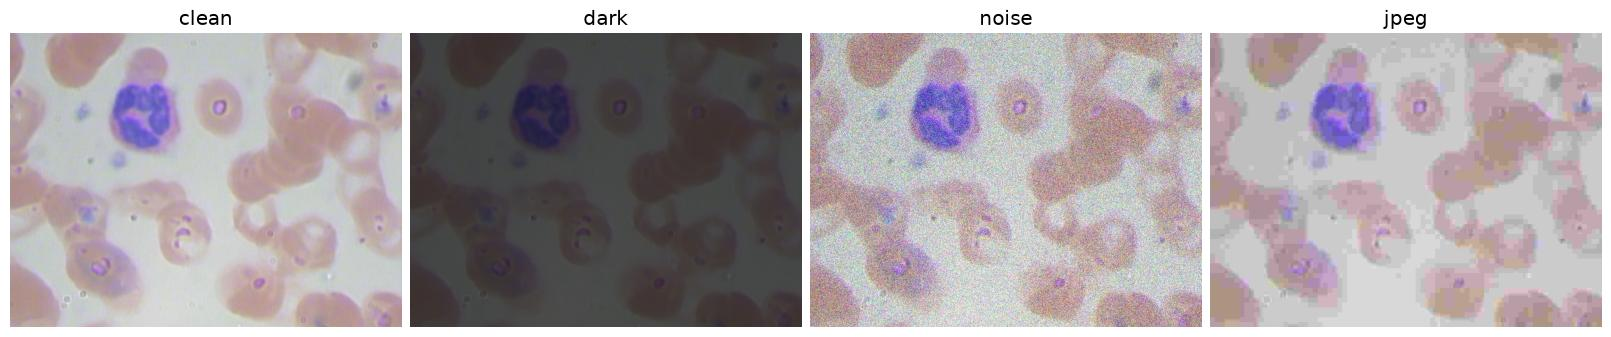

In [33]:
if '6.3' in BONUS_TASKS:
    # ваш код
    corruption_root=DATA_ROOT/'corruptions'
    shifts={}
    shift_rng=np.random.default_rng(SEED)
    examples=[]
    for corruption in ['dark','noise','jpeg']:
        root=corruption_root/corruption
        (root/'images'/'val').mkdir(parents=True,exist_ok=True)
        (root/'labels'/'val').mkdir(parents=True,exist_ok=True)
        for r in records['val']:
            with Image.open(r['image']) as original:
                arr=np.asarray(original.convert('RGB'),dtype=np.float32)
            path=root/'images'/'val'/Path(r['image']).name
            if corruption=='dark':
                Image.fromarray(np.uint8(arr*0.35)).save(path,quality=95)
            elif corruption=='noise':
                noisy=np.clip(arr+shift_rng.normal(0,35,arr.shape),0,255).astype(np.uint8)
                Image.fromarray(noisy).save(path,quality=95)
            else:
                Image.fromarray(arr.astype(np.uint8)).save(path,quality=8,subsampling=2)
            shutil.copy2(YOLO_ROOT/'labels'/'val'/(Path(r['image']).stem+'.txt'),root/'labels'/'val'/(Path(r['image']).stem+'.txt'))
        corrupted_yaml=root/'data.yaml'
        corrupted_yaml.write_text(yaml.safe_dump(dict(path=str(root.resolve()),train=str((YOLO_ROOT/'images'/'train').resolve()),val='images/val',names=dict(enumerate(CLASSES)))))
        result=best.val(data=str(corrupted_yaml),split='val',imgsz=IMGSZ,batch=BATCH,device=DEVICE,workers=WORKERS,
                        conf=0.001,end2end=True,project=str(RUNS.resolve()),name='shift_'+corruption,exist_ok=True,verbose=False)
        shifts[corruption]=summarize_metrics(result)
        examples.append((corruption,root/'images'/'val'/Path(records['val'][0]['image']).name))
    DOMAIN_SHIFT=dict(clean=VAL_FINAL,corrupted=shifts,parameters=dict(dark_factor=0.35,noise_sigma=35,jpeg_quality=8))
    print(json.dumps(DOMAIN_SHIFT,ensure_ascii=False,indent=2))
    fig,axes=plt.subplots(1,4,figsize=(16,4),constrained_layout=True)
    for ax,(name,path) in zip(axes,[('clean',records['val'][0]['image'])]+examples):
        ax.imshow(Image.open(path));ax.set_title(name);ax.axis('off')
    plt.show()
    (artifact_dir/'domain_shift.json').write_text(json.dumps(json_ready(DOMAIN_SHIFT),ensure_ascii=False,indent=2))

**Ответ:** Использованы три фиксированных сдвига без изменения геометрии и GT: яркость ×0.35, независимый Gaussian noise σ=35/255 и JPEG quality=8; seed шума фиксирован. В DOMAIN_SHIFT приведены mAP50/mAP50–95 и поклассовые значения на том же val, поэтому падение можно сопоставить с чистой копией. Для затемнения подходит усиление hsv_v/RandomBrightness, для шума — GaussianNoise, для JPEG — случайное качество сжатия; выбирать интенсивности следует по train и реалистичным условиям съемки. Самое сильное искажение определяется по фактическому падению mAP50–95, результаты не означают устойчивости к любому клиническому сдвигу. Наибольшее падение mAP50–95 вызвал noise: 0.6373→0.0528 (Δ=-0.5845); наибольшая поклассовая потеря у WBC. dark: mAP50=0.3944, mAP50–95=0.2550; noise: mAP50=0.1134, mAP50–95=0.0528; jpeg: mAP50=0.6547, mAP50–95=0.2974. Шум задается до сохранения JPEG quality=95; его эффективная интенсивность после сжатия может отличаться от исходного σ.

## 6.4 Экспорт и скорость (1 балл)

Экспортируйте дообученную модель в ONNX (`best.export(format='onnx', imgsz=IMGSZ)`; ultralytics сам доставит `onnx`, но надежнее `%pip install onnx onnxruntime`) или ускорьте ее иначе (TensorRT, half precision, квантизация). Сравните задержку на картинку до и после (прогрев, одинаковые условия, укажите устройство) и проверьте, что mAP50 не упал.

**Вопрос.** Во сколько раз ускорилось, за счет чего, и сколько стоило в качестве?

In [34]:
if '6.4' in BONUS_TASKS:
    # ваш код
    if any(importlib.util.find_spec(pkg) is None or importlib.metadata.version(pkg) != ver for pkg,ver in {'onnx':'1.23.2','onnxruntime':'1.32.0'}.items()):
        subprocess.run([sys.executable,'-m','pip','install','onnx==1.23.2','onnxruntime==1.32.0'],check=True)
    import onnxruntime as ort
    export_model=YOLO(run_dir/'weights'/'best.pt')
    exported_path=Path(export_model.export(format='onnx',imgsz=IMGSZ,batch=1,device='cpu',simplify=False,
                                         dynamic=False,opset=17,half=False,end2end=True))
    session=ort.InferenceSession(str(exported_path),providers=['CPUExecutionProvider'],
                                sess_options=(lambda s:(setattr(s,'intra_op_num_threads',4),s)[1])(ort.SessionOptions()))
    cpu_model=YOLO(run_dir/'weights'/'best.pt').model.to('cpu').float().eval()
    cpu_model.model[-1].end2end=True
    cpu_model=cpu_model.fuse()
    input_array=np.random.default_rng(SEED).random((1,3,IMGSZ,IMGSZ),dtype=np.float32)
    tensor=torch.from_numpy(input_array)
    def torch_forward():
        with torch.inference_mode():
            return cpu_model(tensor)
    def onnx_forward():
        return session.run(None,{session.get_inputs()[0].name:input_array})
    def forward_benchmark(fn):
        for _ in range(5):fn()
        measurements=[]
        for _ in range(20):
            t=time.perf_counter();fn();measurements.append((time.perf_counter()-t)*1000)
        return dict(mean_ms=float(np.mean(measurements)),median_ms=float(np.median(measurements)),std_ms=float(np.std(measurements)))
    torch.set_num_threads(4)
    pt_timing,onnx_timing=forward_benchmark(torch_forward),forward_benchmark(onnx_forward)
    onnx_detector=YOLO(str(exported_path),task='detect')

    from scipy.optimize import linear_sum_assignment
    comparison_path=str(records['val'][0]['image'])
    comparison_args=dict(imgsz=IMGSZ,rect=False,conf=0.25,nms=False,device='cpu',verbose=False)
    pt_boxes=YOLO(run_dir/'weights'/'best.pt').predict(comparison_path,**comparison_args)[0].boxes.cpu()
    ort_boxes=onnx_detector.predict(comparison_path,**comparison_args)[0].boxes.cpu()
    overlaps=box_iou_np(pt_boxes.xyxy.numpy(),ort_boxes.xyxy.numpy())
    wrong_class=pt_boxes.cls.numpy()[:,None]!=ort_boxes.cls.numpy()[None,:]
    rows,cols=linear_sum_assignment(1-overlaps+100*wrong_class)
    assert len(pt_boxes)==len(ort_boxes)>0 and not wrong_class[rows,cols].any()
    prediction_equivalence=dict(image=Path(comparison_path).name,n_boxes=len(rows),
                                min_matched_iou=float(overlaps[rows,cols].min()),
                                max_box_diff_px=float(np.max(np.abs(pt_boxes.xyxy.numpy()[rows]-ort_boxes.xyxy.numpy()[cols]))),
                                max_score_diff=float(np.max(np.abs(pt_boxes.conf.numpy()[rows]-ort_boxes.conf.numpy()[cols]))))
    assert prediction_equivalence['min_matched_iou']>0.999 and prediction_equivalence['max_score_diff']<1e-4

    onnx_result=onnx_detector.val(data=str(DATA_YAML),split='val',imgsz=IMGSZ,batch=1,device='cpu',workers=0,
                                   conf=0.001,end2end=True,rect=False,project=str(RUNS.resolve()),name='onnx_val',exist_ok=True,verbose=False)
    pt_cpu_result=YOLO(run_dir/'weights'/'best.pt').val(data=str(DATA_YAML),split='val',imgsz=IMGSZ,batch=1,device='cpu',workers=0,
                                                    conf=0.001,end2end=True,rect=False,project=str(RUNS.resolve()),name='pt_cpu_val',exist_ok=True,verbose=False)
    ONNX_RESULT=dict(torch=pt_timing,onnx=onnx_timing,speedup=pt_timing['mean_ms']/onnx_timing['mean_ms'],
                     torch_metrics=summarize_metrics(pt_cpu_result),onnx_metrics=summarize_metrics(onnx_result),
                     prediction_equivalence=prediction_equivalence,device=f'{platform.machine()} CPU; 4 threads; FP32; batch=1; forward only; square {IMGSZ}',
                     warmup=5,repeats=20,onnxruntime_version=ort.__version__,onnx_version=importlib.metadata.version('onnx'))
    ONNX_RESULT['map50_change']=ONNX_RESULT['onnx_metrics']['map50']-ONNX_RESULT['torch_metrics']['map50']
    print(json.dumps(ONNX_RESULT,ensure_ascii=False,indent=2))
    shutil.copy2(exported_path,artifact_dir/'best.onnx')
    (artifact_dir/'onnx.json').write_text(json.dumps(json_ready(ONNX_RESULT),ensure_ascii=False,indent=2))

WARNING ⚠️ 'end2end=True' is deprecated and will be removed in the future. Use 'nms=False' instead.


WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.


Ultralytics 8.4.216 🚀 Python-3.12.11 torch-2.15.0 CPU (Apple M3 Pro)


YOLO26n summary (fused): 122 layers, 2,390,221 parameters, 0 gradients, 5.4 GFLOPs



PyTorch: starting from 'runs_hw2/finetune/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 300, 6) (5.2 MB)



ONNX: starting export with onnx 1.23.2 opset 17...


... (46 outputs left out)

                   all         54        704      0.824      0.909      0.906      0.626


Speed: 0.2ms preprocess, 28.3ms inference, 0.0ms loss, 0.0ms postprocess per image


Results saved to ./runs_hw2/pt_cpu_val


{
  "torch": {
    "mean_ms": 25.135602099999232,
    "median_ms": 25.040041499778454,
    "std_ms": 0.5718345676343441
  },
  "onnx": {
    "mean_ms": 21.766689699961717,
    "median_ms": 21.784937499433,
    "std_ms": 0.1302573060249569
  },
  "speedup": 1.1547737596518153,
  "torch_metrics": {
    "map50": 0.9064354944842034,
    "map50_95": 0.6264034719390751,
    "precision": 0.8236482099388147,
    "recall": 0.9094639933045778,
    "per_class": {
      "RBC": {
        "precision": 0.6616531807298361,
        "recall": 0.8395030910248444,
        "map50": 0.8256269227645918,
        "map50_95": 0.5948843435091824
      },
      "WBC": {
        "precision": 0.9861112830106162,
        "recall": 1.0,
        "map50": 0.995,
        "map50_95": 0.8088948328723908
      },
      "Platelets": {
        "precision": 0.823180166075992,
        "recall": 0.8888888888888888,
        "map50": 0.8986795606880184,
        "map50_95": 0.47543123943565213
      }
    }
  },
  "onnx_metrics": 

**Ответ:** ONNX и PyTorch FP32 сравниваются на одном CPU при batch=1, четырех потоках, квадратном тензоре 640, пяти прогревах и 20 измерениях; учитывается только forward без чтения/letterbox/NMS, поэтому сравнение не смешивает MPS и CPU. Средняя, медианная задержки, стандартное отклонение и коэффициент ускорения приведены в ONNX_RESULT. Качество обоих форматов дополнительно измеряется одинаковым val при batch=1 и conf=0.001; приведены ΔmAP50 и точность сопоставленных предсказаний. Выигрыш возможен за счет оптимизации графа и CPU kernels, однако экспорт сам по себе не гарантирует ускорения; фактический результат описан ниже. Фактически PyTorch 25.14±0.57 мс, ONNX 21.77±0.13 мс, отношение 1.15×; ΔmAP50=+0.000000. На реальном BloodImage_00032.jpg сопоставлено 17 предсказаний: минимальный IoU соответствующих рамок 0.999998, max ошибка координат 0.000092 пикселя, score 0.00000283; сопоставление по классу и IoU не зависит от перестановок TopK. Ускорение подтверждено без изменения mAP50 в измеренной точности. При одинаковом rect=False mAP50 PyTorch/ONNX = 0.9064/0.9064; от таблицы 4.2 эти значения отличаются режимом padding, который здесь зафиксирован одинаково для обеих реализаций.

## 6.5 Пороги (1 балл)

Посмотрите, как порог уверенности `conf` и порог IoU в NMS (`iou`) меняют precision, recall и mAP на val (сетка хотя бы 4 x 2). Учтите, что YOLO26 по умолчанию работает end-to-end без NMS: проверьте, влияет ли `iou` вообще, и сравните с `end2end=False` (ветка one2many + NMS).

**Вопрос.** Какой `conf` вы бы выбрали для своей задачи и почему? Почему mAP почти не зависит от `conf`, а P и R зависят сильно? Влияет ли `iou` в end-to-end режиме?

In [35]:
if '6.5' in BONUS_TASKS:
    # ваш код
    def fixed_threshold_metrics(predictions,ground_truth,n_classes):
        tp=np.zeros(n_classes,dtype=int);fp=np.zeros(n_classes,dtype=int);support=np.zeros(n_classes,dtype=int)
        for p,g in zip(predictions,ground_truth):
            support+=np.bincount(g['labels'],minlength=n_classes)
            used=np.zeros(len(g['labels']),dtype=bool)
            overlaps=box_iou_np(p['boxes'],g['boxes'])
            for i in np.argsort(-p['scores'],kind='stable'):
                c=int(p['labels'][i])
                options=np.flatnonzero((g['labels']==c)&~used&(overlaps[i]>=0.5))
                if len(options):
                    j=options[np.argmax(overlaps[i,options])];used[j]=True;tp[c]+=1
                else:fp[c]+=1
        precision=np.divide(tp,tp+fp,out=np.zeros(n_classes,dtype=float),where=tp+fp>0)
        recall=np.divide(tp,support,out=np.zeros(n_classes,dtype=float),where=support>0)
        p_micro=float(tp.sum()/max((tp+fp).sum(),1));r_micro=float(tp.sum()/max(support.sum(),1))
        return dict(macro_f1=float(np.mean(2*precision*recall/np.maximum(precision+recall,1e-12))),precision=p_micro,recall=r_micro,f1=2*p_micro*r_micro/max(p_micro+r_micro,1e-12),
                    per_class={CLASSES[c]:dict(precision=float(precision[c]),recall=float(recall[c])) for c in range(n_classes)})
    threshold_rows=[]
    end2end_predictions={}
    for end2end in [True,False]:
        mode_detector=YOLO(run_dir/'weights'/'best.pt')
        for nms_iou in [0.3,0.7]:
            low_conf_preds=predict_records(mode_detector,records['val'],conf=0.001,end2end=end2end,iou=nms_iou)
            if end2end:end2end_predictions[nms_iou]=low_conf_preds
            for conf in [0.001,0.05,0.25,0.5]:
                filtered=[{key:value[p['scores']>=conf] for key,value in p.items()} for p in low_conf_preds]
                summary=fixed_threshold_metrics(filtered,records['val'],len(CLASSES))
                map50,aps=evaluate_map50(filtered,records['val'],len(CLASSES))
                threshold_rows.append(dict(end2end=end2end,iou=nms_iou,conf=conf,map50=map50,**summary))
    end2end_iou_equal=all(all(np.array_equal(a[k],b[k]) for k in a) for a,b in zip(end2end_predictions[0.3],end2end_predictions[0.7]))
    selected_micro=max([r for r in threshold_rows if r['end2end']],key=lambda r:r['f1'])
    selected_threshold=max([r for r in threshold_rows if r['end2end']],key=lambda r:r['macro_f1'])
    THRESHOLDS=dict(rows=threshold_rows,end2end_iou_identical=end2end_iou_equal,selected=selected_threshold,selected_micro=selected_micro,
                    criterion='maximum macro F1 on val at IoU=0.5; test not used')
    display(Markdown('|end2end|iou|conf|P micro|R micro|F1 micro|F1 macro|mAP50|\n|---|---|---|---|---|---|---|---|\n'+
                     '\n'.join(f"|{r['end2end']}|{r['iou']}|{r['conf']}|{r['precision']:.3f}|{r['recall']:.3f}|{r['f1']:.3f}|{r['macro_f1']:.3f}|{r['map50']:.3f}|" for r in threshold_rows)))
    print('E2E predictions identical for both iou:',end2end_iou_equal,'Selected:',selected_threshold)
    (artifact_dir/'thresholds.json').write_text(json.dumps(json_ready(THRESHOLDS),ensure_ascii=False,indent=2))

WARNING ⚠️ 'end2end=True' is deprecated and will be removed in the future. Use 'nms=False' instead.


WARNING ⚠️ 'end2end=True' is deprecated and will be removed in the future. Use 'nms=False' instead.


WARNING ⚠️ 'end2end=True' is deprecated and will be removed in the future. Use 'nms=False' instead.


WARNING ⚠️ 'end2end=True' is deprecated and will be removed in the future. Use 'nms=False' instead.


WARNING ⚠️ 'end2end=True' is deprecated and will be removed in the future. Use 'nms=False' instead.


WARNING ⚠️ 'end2end=True' is deprecated and will be removed in the future. Use 'nms=False' instead.


... (8 outputs left out)

WARNING ⚠️ 'end2end=False' is deprecated and will be removed in the future. Use 'nms=None' instead.


WARNING ⚠️ 'end2end=False' is deprecated and will be removed in the future. Use 'nms=None' instead.


|end2end|iou|conf|P micro|R micro|F1 micro|F1 macro|mAP50|
|---|---|---|---|---|---|---|---|
|True|0.3|0.001|0.089|0.991|0.164|0.187|0.902|
|True|0.3|0.05|0.404|0.973|0.571|0.724|0.897|
|True|0.3|0.25|0.603|0.903|0.723|0.843|0.854|
|True|0.3|0.5|0.736|0.786|0.760|0.799|0.729|
|True|0.7|0.001|0.089|0.991|0.164|0.187|0.902|
|True|0.7|0.05|0.404|0.973|0.571|0.724|0.897|
|True|0.7|0.25|0.603|0.903|0.723|0.843|0.854|
|True|0.7|0.5|0.736|0.786|0.760|0.799|0.729|
|False|0.3|0.001|0.162|0.950|0.277|0.293|0.879|
|False|0.3|0.05|0.428|0.929|0.586|0.747|0.873|
|False|0.3|0.25|0.570|0.903|0.699|0.831|0.868|
|False|0.3|0.5|0.707|0.807|0.754|0.835|0.783|
|False|0.7|0.001|0.054|0.989|0.103|0.160|0.890|
|False|0.7|0.05|0.356|0.967|0.520|0.707|0.885|
|False|0.7|0.25|0.553|0.920|0.691|0.829|0.877|
|False|0.7|0.5|0.705|0.811|0.754|0.840|0.789|

E2E predictions identical for both iou: True Selected: {'end2end': True, 'iou': 0.3, 'conf': 0.25, 'map50': 0.8544507644942275, 'macro_f1': 0.8433490856122794, 'precision': 0.6028436018957346, 'recall': 0.9034090909090909, 'f1': 0.7231381466742468, 'per_class': {'RBC': {'precision': 0.5662778366914104, 'recall': 0.898989898989899}, 'WBC': {'precision': 0.9824561403508771, 'recall': 1.0}, 'Platelets': {'precision': 0.8363636363636363, 'recall': 0.8518518518518519}}}


**Ответ:** Проверена сетка 4×2 отдельно для end2end=True и False: conf∈{0.001, 0.05, 0.25, 0.5}, iou∈{0.3, 0.7}. P/R здесь считаются собственным matching при IoU≥0.5 и именно заданном conf; это micro-метрики, в отличие от средних по классам и оптимальной рабочей точки Ultralytics. Выбран conf с максимальным macro-F1 на val, чтобы численное преобладание RBC не подавляло другие классы; при приоритете пропусков клеток дополнительно нужен минимальный приемлемый recall и экспертная проверка. AP оценивает ранжирование по всем оставшимся score: небольшое отсечение слабого хвоста часто мало влияет на AP, но высокий conf может существенно снизить и AP, и recall, поэтому неизменность mAP не является общим правилом. В end-to-end нет NMS, влияние iou проверено прямым сравнением массивов предсказаний; в one2many+NMS меньший iou агрессивнее подавляет перекрывающиеся рамки, что особенно важно для плотных клеточных сцен. По maximum macro-F1 на val выбран conf=0.25: macro-F1=0.8433, P micro=0.6028, R micro=0.9034, F1 micro=0.7231. Максимум micro-F1 достигается при conf=0.5, но recall Platelets там 0.5185 против 0.8519 у выбранного порога, поэтому для трех классов предпочтен macro-критерий. Совпадение массивов end-to-end при двух iou: True; для этого пути iou не меняет предсказания в данном эксперименте.